# Thesis research overview
### Source-separated restaurant summarization: Yelp, TripAdvisor and Qwen
**Supervisor review edition · 15 November 2026 · completed results frozen through 6 November 2026**

This notebook connects actual implementation excerpts to preserved research evidence.
Tables, figures and complete illustrative outputs are already displayed. **Reading needs no
Python installation:** open the accompanying HTML. Run All uses only small, bundled local
exports; it never trains, generates summaries, downloads models, calls an API or changes ratings.

**Findings.** Aligned captions substantially outperform Shuffled visual evidence. Filtering
reduces surface repetition, but does not consistently outperform U. On the small TripAdvisor
comparison, Qwen-Caption receives higher ratings than LED on five criteria. LED has lower
measured prepared-input generation time and allocator-memory peaks; complete end-to-end
efficiency was not measured. These are qualified tradeoffs, not a universal system ranking.

**Reading map:** 1 Design → 2 Splits → 3 Review budgets → 4 Captions/filtering → 5 Targets/LoRA
→ 6 Frozen selection → 7 Validation Teacher agreement → 8 TEST100 reference metrics
→ 9 TEST30 ratings → 10 Yelp examples → 11 TripAdvisor → 12 Qwen → 13 External example
→ 14 Efficiency → 15 Discussion → 16 Reproducibility.

**Public source-code edition.** Original Yelp/TripAdvisor reviews, photos and private recovery catalogs are not distributed. Generated outputs, numerical results, plots and scientific limitations are retained. Complete source inspection requires the separately restricted evidence archive.

In [1]:
from pathlib import Path
import hashlib, html, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Code

# Launch Jupyter from the extracted package directory; no original repository path is needed.
BASE = Path.cwd()
assert (BASE / 'data/test100_per_business.csv').is_file(), 'Open this notebook in the extracted package folder.'
def load(name):
    return json.loads((BASE / 'data' / name).read_text(encoding='utf-8'))
def table(name):
    return pd.read_csv(BASE / 'data' / name)
def implementation(name):
    binding = load('code_provenance.json')[name]
    display(Markdown('**Original implementation:** `' + binding['file'] + '`; lines ' + str(binding['line_spans'])
                     + '. Source-file SHA-256: `' + binding['sha256'] + '`. Display only; not executed here.'))
    display(Code((BASE / binding['excerpt']).read_text(encoding='utf-8'), language='python'))
import sys
sys.dont_write_bytecode = True
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
COLORS = {'RO':'#697586', 'U':'#d68b29', 'F':'#167a80', 'S':'#a95c89'}
ORDER = ['RO', 'U', 'F', 'S']
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_colwidth', 90)
manifest = load('package_data_manifest.json')
for item in manifest:
    p = BASE / item['file']
    assert p.stat().st_size == item['bytes']
    assert hashlib.sha256(p.read_bytes()).hexdigest() == item['sha256'], item['file']
print(f'PASS: {len(manifest)} bundled evidence/code files verified by byte size and SHA-256.')

from verify_extension import verify as verify_external, records as external_records
print(json.dumps(verify_external(BASE), indent=2))

PASS: 65 bundled evidence/code files verified by byte size and SHA-256.
{
  "O": {
    "records": 90,
    "restaurants": 15,
    "descriptive_rows_checked": 54,
    "agreement_rows_checked": 17,
    "paired_point_estimates_checked": 11
  },
  "P": {
    "records": 90,
    "restaurants": 15,
    "descriptive_rows_checked": 54,
    "agreement_rows_checked": 18,
    "paired_point_estimates_checked": 18
  },
  "scope": "Existing records, mapping/output hashes, descriptive arithmetic, kappa and paired point estimates. No model execution or participant authentication."
}


## 1. Research objectives and controlled comparisons
The system produces two explicitly separated components: **Review Consensus**, supported only by
selected reviews, and **Visual Evidence**, supported by image captions. The research asks whether
captions add useful information, whether filtering improves that information, and whether correct
business-to-caption alignment matters.

| Condition | Review input | Visual input | Interpretation |
|---|---|---|---|
| RO | Frozen selected reviews + metadata | None | Review-only pipeline |
| U | Same selected reviews + metadata | Basic-quality captions, deterministic selection | Unfiltered caption pipeline |
| F | Same selected reviews + metadata | Relevance/redundancy/diversity-filtered captions | Selected Source-Separated V1-S1000 |
| S | Exactly F Review output | F captions reassigned from another business | Alignment negative control; F adapter |

Source separation is shared across final conditions. The historical Original CE3 used joint inputs;
it is a parent and validation comparator, **not the final F checkpoint**. Pipeline differences include
training ancestry and supervision, so this is not a perfectly isolated causal test of filtering alone.

## 2. Dataset preparation and frozen splits
Restaurant eligibility requires at least ten reviews and five local photos, with accommodation
businesses excluded. English-review eligibility is checked before final selection. Sorted eligible
business IDs are sampled deterministically with seed 42; the frozen order allocates 2,000/200/100.
Training, validation and TEST have disjoint **business IDs**. TEST is reserved for final evaluation;
it is not used for checkpoint or filter selection.

Business-disjoint splitting does not guarantee image-content independence. The later image audit
found cross-split reuse affecting 17 TEST businesses; the primary evaluation retains all 100.

,businesses,raw_reviews,photos
split,,,
train,2000,530181,26387
validation,200,46163,2504
test,100,25149,1136


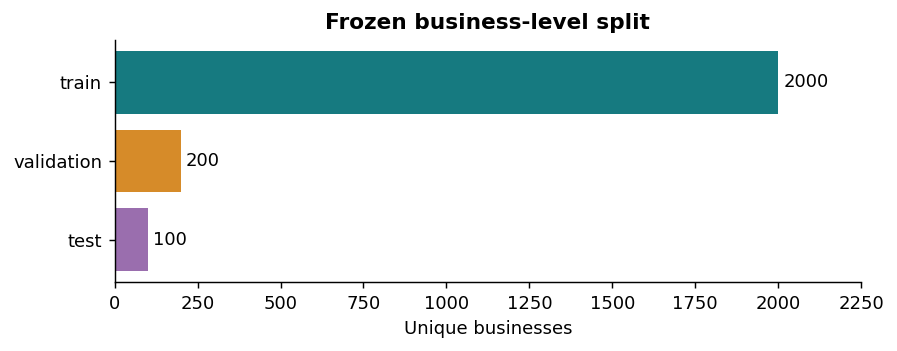

In [2]:
splits = table('business_split.csv')
assert len(splits) == splits.business_id.nunique() == 2300
assert splits.groupby('split').size().to_dict() == {'test':100, 'train':2000, 'validation':200}
split_counts = splits.groupby('split').agg(businesses=('business_id','size'),
                                         raw_reviews=('raw_review_records','sum'),
                                         photos=('local_photo_records','sum')).reindex(['train','validation','test'])
display(split_counts)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(split_counts.index[::-1], split_counts.businesses[::-1], color=['#9a6eae','#d68b29','#167a80'])
for i, value in enumerate(split_counts.businesses[::-1]):
    ax.text(value+15, i, str(value), va='center')
ax.set(xlabel='Unique businesses', xlim=(0,2250), title='Frozen business-level split')
plt.tight_layout(); plt.show()

## 3. Representative review selection and source budgets
The accepted v4.2 selector keeps **whole English reviews**, with a maximum of 30 per business.
Star-rating quotas and time strata preserve positive, mixed and negative experiences. A secondary
source-length-distribution refinement swaps within star/time cells: it preserves review count and
both histograms while respecting the budget. It does not simply choose the shortest reviews.

Frozen allocations are **4,000 review tokens**, **750 incremental caption tokens** and **5,000
complete-source tokens**. The caption increment includes formatting overhead, not just caption words.
Selection/packing never silently cuts review or caption text. Token counts below are recorded with
the pinned tokenizer; rerunning this notebook does not download or tokenize with a different model.

In [3]:
budgets = table('source_budget_ledger.csv')
assert len(budgets) == 6900 and not budgets.duplicated(['business_id','condition']).any()
assert budgets.business_id.nunique() == 2300
assert budgets.n_reviews.between(1,30).all()
assert budgets.review_block_tokens_with_special.le(4000).all()
assert budgets.caption_block_increment_tokens.le(750).all()
assert budgets.full_source_tokens.le(5000).all()
assert not budgets[['review_budget_overflow','caption_budget_overflow','source_budget_overflow']].any().any()
display(budgets.groupby('condition').agg(rows=('business_id','size'),
    mean_reviews=('n_reviews','mean'), max_reviews=('n_reviews','max'),
    mean_caption_count=('n_captions','mean'), max_review_tokens=('review_block_tokens_with_special','max'),
    max_caption_increment=('caption_block_increment_tokens','max'), max_source_tokens=('full_source_tokens','max')).round(2))
print('PASS: all 6,900 frozen condition/source records satisfy the original budgets.')
implementation('review_selection')

,rows,mean_reviews,max_reviews,mean_caption_count,max_review_tokens,max_caption_increment,max_source_tokens
condition,,,,,,,
filtered,2300,28.43,30,3.44,4000,141,4213
reviews_only,2300,28.43,30,0.00,4000,0,4086
unfiltered,2300,28.43,30,4.99,4000,152,4211


PASS: all 6,900 frozen condition/source records satisfy the original budgets.


**Original implementation:** `scripts/budget_aware_review_selection_v4_2.py`; lines [[19, 22], [35, 61]]. Source-file SHA-256: `04a9535cd24a3443d82b6106c1c29189ebd324639c242c043c84120b5cfb1ceb`. Display only; not executed here.

def signature(ev,ids):
    stars=Counter(int(ev.by_id[rid]['stars']) for rid in ids)
    times=Counter(ev.bins[rid] for rid in ids)
    return (len(ids),tuple(stars[i] for i in range(1,6)),tuple(times[i] for i in range(5)))

def refine(ev,initial,group,profile,rules,budget):
    current=initial;feasible={c['ids']:c for c in group};trace=[];evaluated=[]
    assigned=profile[1];opts=ev.cfg['secondary_length_balance']
    for iteration in range(opts['refinement_iterations']):
        proposals={};present=set(current['ids'])
        for outgoing in current['ids']:
            cell=(int(ev.by_id[outgoing]['stars']),ev.bins[outgoing])
            for length_bin in range(len(profile[2])):
                available=sorted((rid for rid in ev.cells[cell] if rid not in present and assigned[rid]==length_bin),key=ev.position.__getitem__)
                if not available:continue
                rng=random.Random(stable_seed(rules['seed'],rules['algorithm_version'],ev.bid,'secondary_length',budget,iteration,outgoing,length_bin))
                incoming=available[rng.randrange(len(available))]
                ids=ev.canonical([rid for rid in current['ids'] if rid!=outgoing]+[incoming])
                proposals[ids]={'out':outgoing,'in':incoming}
        ranked=sorted(proposals,key=lambda ids:(length_score(ids,profile),priority(ids,rules,ev.bid,'secondary_proposal',budget,iteration),ids))
        shortlist=ranked[:opts['exact_proposals_per_iteration']];iteration_candidates=[current]
        for ids in shortlist:
            c=ev.evaluate(ids,{'type':'secondary_same_cell_proposal','budget':budget,'iteration':iteration,'operation':proposals[ids],'before_ids':list(current['ids'])})
            assert signature(ev,c['ids'])==signature(ev,initial['ids'])
            evaluated.append(c)
            if c['tokens']<=budget:feasible[c['ids']]=c;iteration_candidates.append(c)
        best=secondary_choice(iteration_candidates,profile,rules,ev.bid)
        improved=length_score(best['ids'],profile)<length_score(current['ids'],profile)-1e-12
        trace.append({'iteration':iteration,'structural_proposals':len(proposals),'exact_proposals':len(shortlist),'unevaluated_not_certified':len(proposals)-len(shortlist),'before_ids':list(current['ids']),'best_ids':list(best['ids']),'accepted':improved,'length_jsd_before':length_score(current['ids'],profile),'length_jsd_best':length_score(best['ids'],profile),'tokens_before':current['tokens'],'tokens_best':best['tokens']})
        if not improved:break
        current=best
    return secondary_choice(list(feasible.values()),profile,rules,ev.bid),list(feasible.values()),trace,evaluated

## 4. Image captions and Filtered versus Unfiltered construction
BLIP-2 (`Salesforce/blip2-opt-2.7b-coco`, pinned revision in the next cell) captions **all eligible
photos before K selection**. Generation uses beam 3, no sampling, maximum 64 new tokens; a failed
Basic-quality check permits one fixed-prompt retry. Basic checks are not factuality certification.

**U:** Basic-passing pool → fixed-seed photo order → at most K captions.

**F:** Basic-passing pool → exact normalized-pixel duplicate collapse → relevance margin ≥0.08
→ semantic redundancy reduction at 0.59 → diversity ordering → at most **K=5**.
Broader scene grouping uses complete-link threshold 0.46. CLIP supplies a **soft quality ranking**,
never a hard rejection threshold. pHash is diagnostic only. Captions themselves are not rewritten.
K=5 is the smallest feasible choice meeting the validation-only 95%-of-best coverage rule.

CLIP ViT-B/32 ranks normalized image–caption cosine agreement. SBERT `all-mpnet-base-v2`
provides normalized, attention-mask-mean caption embeddings. Relevance is the maximum cosine to
six dining-domain prototypes minus the maximum cosine to six unrelated-domain prototypes; it
checks dining-domain relevance, not exact business identity or factual truth. Redundancy uses
greedy representative cosine similarity; farthest-first diversity maximizes minimum distance
(1 − cosine), with quality/photo-ID tie-breaking. The exact pinned scoring protocol is bundled.

K is a ceiling, not a quota. Empty Filtered pools are valid and retained. F's selected photos need
not be a subset of U's selected five, since both select from the complete pool differently.

,Frozen setting
model_id,Salesforce/blip2-opt-2.7b-coco
model_revision,cda95b9319b722f79c9451a3d8ff92eea02048dc
K,5
CLIP,soft_quality_order_only
pHash,diagnostic_only
caption_thresholds,"{'relevance': 0.08, 'redundancy': 0.59, 'grouping': 0.46}"
generation,"{'batch_size': 1, 'num_beams': 3, 'do_sample': False, 'max_new_tokens': 64, 'initial_p..."


,businesses,generated,basic_pass,U_selected,F_selected,empty_F
split,,,,,,
train,2000,26387,26331,9989,6880,9
validation,200,2504,2497,998,698,1
test,100,1136,1134,500,341,2


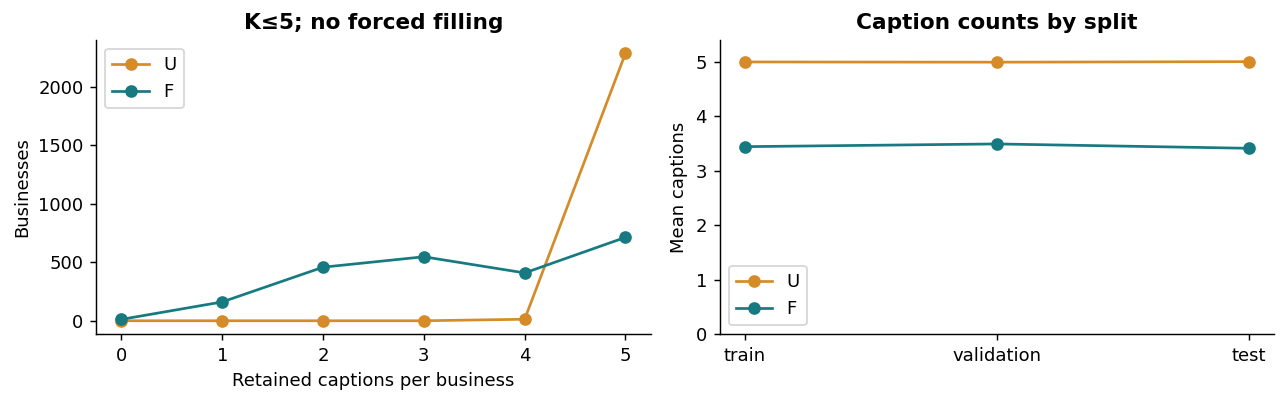

In [4]:
caption_method = load('caption_method.json')
display(pd.Series({k: caption_method[k] for k in ['model_id','model_revision','K','CLIP','pHash','caption_thresholds','generation']}, name='Frozen setting').to_frame())
caption_report = load('caption_completion.json')
caption_rows = []
for split, r in caption_report['split_reports'].items():
    caption_rows.append(dict(split=split, businesses=r['businesses'], generated=r['caption_pool_generated'],
        basic_pass=r['basic_pass'], U_selected=r['conditions']['unfiltered']['retained_captions']['total'],
        F_selected=r['conditions']['filtered']['retained_captions']['total'],
        empty_F=len(r['conditions']['filtered']['zero_caption_businesses'])))
caption_counts = pd.DataFrame(caption_rows).set_index('split')
assert caption_counts.generated.sum() == 30027 and caption_counts.F_selected.sum() == 7919
assert caption_counts.U_selected.sum() == 11487 and caption_counts.empty_F.sum() == 12
display(caption_counts)
fig, axes = plt.subplots(1,2,figsize=(10,3.2))
visual_budget = budgets[budgets.condition.isin(['unfiltered','filtered'])]
for c, label, color in [('unfiltered','U',COLORS['U']),('filtered','F',COLORS['F'])]:
    counts = visual_budget[visual_budget.condition.eq(c)].n_captions.value_counts().reindex(range(6),fill_value=0)
    axes[0].plot(counts.index,counts.values,'o-',label=label,color=color)
    part = visual_budget[visual_budget.condition.eq(c)].groupby('split').n_captions.mean().reindex(['train','validation','test'])
    axes[1].plot(part.index,part.values,'o-',label=label,color=color)
axes[0].set(xlabel='Retained captions per business',ylabel='Businesses',title='K≤5; no forced filling')
axes[1].set(ylabel='Mean captions',ylim=(0,5.4),title='Caption counts by split')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

In [5]:
# Source excerpts are exact, including deterministic tie-breaking.
implementation('filter_relevance')
implementation('filter_exact_duplicates')
implementation('filter_ranking')

**Original implementation:** `scripts/stage_f_d030_protocol.py`; lines [[100, 102], [105, 107]]. Source-file SHA-256: `4b5be2fe74f5ca434bf609484771f353618fa86712ecc5f27d401ceeb0a69093`. Display only; not executed here.

def relevance_eligible(rows,indices,threshold):
    # No CLIP cutoff: CLIP enters only the unchanged Stage F quality_order helpers.
    return [i for i in indices if round(float(rows[i]['relevance_margin']),6)>=threshold]

def unfiltered_fixed_seed_order(rows):
    # Same Basic-only fixed-seed ordering as before D-030, without score filtering.
    return sorted(rows,key=lambda r:hashlib.sha256(('42|Unfiltered|'+r['photo_id']).encode()).hexdigest())

**Original implementation:** `scripts/stage_f_d031_protocol.py`; lines [[101, 108]]. Source-file SHA-256: `2b2111301a588f1e05b39fda504683de9529185bc09462e587727f4c6cb25ab5`. Display only; not executed here.

def exact_duplicate_reduce(rows,pixel_hashes):
    assert len(rows)==len(pixel_hashes) and all(isinstance(h,str) and h for h in pixel_hashes)
    representatives={};kept=[];removed={}
    for i in quality_order(rows):
        pixel=pixel_hashes[i]
        if pixel not in representatives:representatives[pixel]=i;kept.append(i)
        else:removed[i]=representatives[pixel]
    return kept,removed

**Original implementation:** `scripts/stage_f_math.py`; lines [[5, 6], [9, 16], [46, 55]]. Source-file SHA-256: `f061d77b0a2fc870823e80683cc7eb02afefa5e70ac31c00c8202ae6560e65f3`. Display only; not executed here.

def quality_order(rows):
    return sorted(range(len(rows)), key=lambda i:(-round(rows[i]['clip_score'],6),-round(rows[i]['relevance_margin'],6),rows[i]['photo_id']))

def redundancy_reduce(rows, similarity, threshold):
    kept=[];mapping={}
    matrix=np.round(similarity.astype(np.float64),6)
    for i in quality_order(rows):
        duplicate=[j for j in kept if matrix[i,j]>=threshold]
        if not duplicate:kept.append(i)
        else:mapping[i]=min(duplicate,key=lambda j:(-matrix[i,j],rows[j]['photo_id']))
    return kept,mapping

def farthest_first(rows, similarity, candidates):
    quality=quality_order(rows);rank={i:n for n,i in enumerate(quality)}
    remaining=set(candidates)
    if not remaining:return []
    selected=[min(remaining,key=lambda i:rank[i])];remaining.remove(selected[0])
    matrix=np.round(similarity.astype(np.float64),6)
    while remaining:
        i=min(remaining,key=lambda i:(-min(1-matrix[i,j] for j in selected),rank[i]))
        selected.append(i);remaining.remove(i)
    return selected

## 5. Teacher supervision and LED-large Expanded LoRA
The accepted Teacher corpus contains **6,600 condition records** for 2,000 TRAIN and 200 VALIDATION
businesses (RO/U/F). Review targets are byte-identical across conditions. U and F Visual targets
are condition-specific and differ for all 2,200 businesses. No canonical Stage G TEST Teacher
targets exist. The provider model alias is recorded; an immutable backend snapshot is not attested.
Automated target acceptance does not prove every Teacher claim factual.

The final summarizer uses `allenai/led-large-16384`, one **shared Expanded LoRA** adapter per model
(rank 8, alpha 16, dropout 0; 456 trainable tensors / 4,915,200 parameters). Review-only and
caption-only task views independently tokenize their original component labels; padding is masked
with −100 and target EOS is preserved. BOS is the only globally attended source position.

F continues the original CE3 step-750 adapter for **1,000 successful updates**: two passes through
TRAIN2000, 4 Review + 4 Visual microbatches per update, physical batch 1 / accumulation 8,
native cross-entropy, AdamW, FP16 autocast, LR 2e−5, warmup 25 and linear horizon 1,000.
Review and Visual each receive 4,000 successful presentations. Final inference uses the original
V1 targets, not a later relabeling experiment.

In [6]:
teacher = load('teacher_provenance.json')
display(pd.DataFrame(teacher['equivalence']))
assert teacher['records'] == 6600 and teacher['TEST_target_records_in_canonical_Stage_G'] == 0
method = load('model_and_method.json')
display(pd.Series(method['adapter'], name='Shared Expanded LoRA').to_frame())
display(pd.Series({k: method['F_optimization'][k] for k in ['physical_batch','accumulation','successful_updates','per_window','learning_rate','warmup_steps','scheduler','optimizer','precision']}, name='F training contract').to_frame())
implementation('label_collation')
implementation('native_training_step')

,split,businesses,RO_U_F_Review_byte_identical,U_F_Visual_byte_identical,U_F_Visual_different
0,train,2000,2000,0,2000
1,validation,200,200,0,200


,Shared Expanded LoRA
r,8
lora_alpha,16
lora_dropout,0.0
target_modules,"[value, output, v_proj, fc2, key_global, out_proj, query, fc1, k_proj, value_global, q..."


,F training contract
physical_batch,1
accumulation,8
successful_updates,1000
per_window,"{'review': 4, 'visual': 4}"
learning_rate,0.00002
warmup_steps,25
scheduler,linear_1000_update_horizon_then_stop
optimizer,fresh_adamw_torch
precision,Original CE3 FP16 autocast / FP32 parameters and AdamW moments / native GradScaler


**Original implementation:** `scripts/stage_hi_led_data.py`; lines [[73, 106]]. Source-file SHA-256: `7ce7b0a87935cca43ca4b2c354bd0e3eecadfa05c033692a9b5e96133764b467`. Display only; not executed here.

class LEDCompleteCollator:
    def __init__(self, source_limit=5000, label_limit=768, window=1024, pad_source_to=None, pad_label_to=None):
        self.source_limit, self.label_limit, self.window = source_limit, label_limit, window
        self.pad_source_to, self.pad_label_to = pad_source_to, pad_label_to

    def __call__(self, features):
        import torch
        require(features, 'Empty batch')
        for f in features:
            require(0 < len(f['input_ids']) <= self.source_limit, 'Source overflow; no truncation permitted')
            require(0 < len(f['labels']) <= self.label_limit, 'Label overflow; no truncation permitted')
            require(f['input_ids'][0] == f['labels'][0] == 0 and f['input_ids'][-1] == f['labels'][-1] == 2, 'Incomplete BOS/EOS')
        source_max = max(len(f['input_ids']) for f in features)
        label_max = max(len(f['labels']) for f in features)
        # Padding is not counted as content and may exceed the logical source cap.
        sl = ((source_max + self.window-1)//self.window)*self.window
        ll = min(self.label_limit, ((label_max+7)//8)*8)
        if self.pad_source_to is not None:
            require(self.pad_source_to >= sl and self.pad_source_to % self.window == 0, 'Invalid stress source shape')
            sl = self.pad_source_to
        if self.pad_label_to is not None:
            require(label_max <= self.pad_label_to <= self.label_limit, 'Invalid stress label shape')
            ll = self.pad_label_to
        ids = torch.full((len(features), sl), 1, dtype=torch.long)
        attention = torch.zeros_like(ids); global_attention = torch.zeros_like(ids)
        labels = torch.full((len(features), ll), -100, dtype=torch.long)
        for i, f in enumerate(features):
            n, m = len(f['input_ids']), len(f['labels'])
            ids[i, :n] = torch.tensor(f['input_ids'], dtype=torch.long)
            attention[i, :n] = 1; global_attention[i, 0] = 1
            labels[i, :m] = torch.tensor(f['labels'], dtype=torch.long)
        require(torch.equal(global_attention.sum(1), torch.ones(len(features), dtype=torch.long)), 'Global attention count wrong')
        require(not torch.any(global_attention.bool() & ~attention.bool()), 'Global attention on padding')
        return dict(input_ids=ids, attention_mask=attention, global_attention_mask=global_attention, labels=labels)

**Original implementation:** `outputs/stage_i/led_large_source_separated_v1_two_epoch_preparation_v1/downloaded/RUN_TRAIN.py`; lines [[139, 160]]. Source-file SHA-256: `a0904c70675d01ffc9cf2dc8a5011f9d054b79aff04f5bcd9cfcb8e6edd252f4`. Display only; not executed here.

for slot,j in enumerate(indexes):
                    recovery.microbatch();check();t=tasks[j];diagnostics.update(microbatch=slot+1,task_index=j,task=t['task'],business_id=t['business_id'])
                    si=pack['input_ids'][pack['input_offsets'][j]:pack['input_offsets'][j+1]].astype(np.int64).tolist()
                    li=pack['labels'][pack['label_offsets'][j]:pack['label_offsets'][j+1]].astype(np.int64).tolist()
                    batch={k:v.cuda() for k,v in collator([dict(input_ids=si,labels=li)]).items()}
                    need(batch['global_attention_mask'].sum().item()==1 and batch['global_attention_mask'][0,0].item()==1,'BOS mask differs')
                    append(R/'MICROBATCH_START.jsonl',dict(step=step,epoch=(step-1)//500+1,slot=slot+1,task_index=j,business_id=t['business_id'],task=t['task'],
                         replay=recovery.replaying,actual_microbatches=recovery.microbatches,scale=float(scaler.get_scale())))
                    with torch.autocast('cuda',dtype=torch.float16):loss=model(**batch,use_cache=False).loss
                    need(torch.isfinite(loss).item(),'Nonfinite forward CE loss; no recovery')
                    losses.append(float(loss.detach()));scaler.scale(loss/8).backward()
                    append(R/'MICROBATCH_EVIDENCE.jsonl',dict(step=step,epoch=(step-1)//500+1,slot=slot+1,task_index=j,task=t['task'],replay=recovery.replaying,
                         actual_microbatches=recovery.microbatches,CE_loss=losses[-1],scale=float(scaler.get_scale())))
                    del batch,loss
            backward_window()
            def skip():scaler.step(opt);scaler.update()
            norm=recovery.finish(model,opt,scaler,lambda:scaler.unscale_(opt),skip,backward_window)
            gradients=inspect_gradients(model)
            need(gradients['trainable_tensors']==456 and not gradients['missing'] and not gradients['nonfinite'],'Invalid finite gradient window')
            append(R/'GRADIENTS.jsonl',dict(step=step,unscaled_clipped=True,**gradients))
            used_lr=opt.param_groups[0]['lr'];scaler.step(opt);scaler.update();sched.step();torch.cuda.synchronize()
            need(len(opt.state)==456 and {int(v['step']) for v in opt.state.values()}=={step},'Optimizer update accounting differs')

## 6. Final frozen selection and TEST100 inference
F is **Source-Separated V1-S1000**, selected on VALIDATION before TEST comparison, using full-cohort
descriptive diagnostics and a bounded source-grounded qualitative assessment. It was not selected
by training loss or retrospectively chosen from TEST scores. The final RO and U models also have
1,000 new successful updates, but start from their own step-750 parents; F starts from CE3.

RO receives 4 Review microbatches per update divided by 8; U/F receive 4 Review + 4 Visual divided
by 8. Thus matching update counts does not equalize compute or effective loss composition. These
ancestries and supervision histories limit a pure input-only causal interpretation. RO follows its
Review-only RO750 parent with no experiment-specific caption fine-tuning; it is not initialized
from caption-trained CE3. Public pretraining exposure is not exhaustively audited.

Review pass: metadata + selected reviews, no captions → `[REVIEW_CONSENSUS]`.
Visual pass: captions only, no reviews or business metadata → `[VISUAL_EVIDENCE]`.
The sections are combined verbatim. Frozen decoding: beam 4, length penalty 1, no sampling,
max sequence length **768 per call**, no reranking or output repair. This is a per-component budget,
not the same total output budget as historical joint-input CE3.

S uses F weights and a frozen one-to-one caption reassignment. F/S Review is identical; S is not
a separately trained model. The two zero-Filtered-caption businesses have no Visual intervention.
All 400 condition records remain in TEST; there are 700 applicable component records (RO has no Visual).

In [7]:
model_rows = []
for c, r in method['models'].items():
    model_rows.append(dict(condition=c, new_updates=r['successful_new_phase_updates'], parent_updates=r['original_parent_updates'],
        Review_presentations=r['review_presentations_new_phase'], Visual_presentations=r['visual_presentations_new_phase'],
        adapter_sha256=r['adapter_sha256'], parent_adapter_sha256=r['initialization_adapter_sha256']))
display(pd.DataFrame(model_rows).set_index('condition'))
display(Markdown('**Frozen backbone SHA-256:** `' + method['backbone']['sha256'] + '`. These are existing freeze receipts; this small package does not contain or rehash the multi-GB weights.'))

,new_updates,parent_updates,Review_presentations,Visual_presentations,adapter_sha256,parent_adapter_sha256
condition,,,,,,
RO,1000,750,4000,0,2a2fbc2cd76176abb09a43615f12a8c43bfec83dad526798d0c5708333cdda2d,d6c2eb47eefa79f44a21612832706b4a6d49dd10ffae7caf909060c2bcb4890e
U,1000,750,4000,4000,41ecc5691dfda45dbfcac1508bb0dc2eedd0a6ccec76aa650a4b92bcbb6ef535,c2a0ad7c17c8bef44d4f3a702a86a3ae8cc31efa268243b8cc7f2832fa27f22c
F,1000,750,4000,4000,6dcb08275e96f3972b15058f6abf370d83fa8ce05553214af94b5a0bd9c1c699,507dcdd92333dc0625559570f06140b84a14eb202191779ebd03393224090a60
S,1000,750,4000,4000,6dcb08275e96f3972b15058f6abf370d83fa8ce05553214af94b5a0bd9c1c699,507dcdd92333dc0625559570f06140b84a14eb202191779ebd03393224090a60


**Frozen backbone SHA-256:** `b31752450099a5eb3fcd5199001c5a6831e4a32e13f17a287a5aa6e10801d081`. These are existing freeze receipts; this small package does not contain or rehash the multi-GB weights.

## 7. VALIDATION200: agreement with existing Teacher targets
This track measures model–Teacher agreement, not independent human quality. Review uses the common
identical target for RO/U/F. Visual uses U-specific targets for U and F-specific targets for F;
**their Visual scores cannot establish which pipeline is better grounded**. Each row includes all
200 businesses. The compact bundle contains the corresponding per-business frozen metrics.

In [8]:
metric_columns = ['rouge1_fmeasure','rouge2_fmeasure','rougeL_fmeasure','bertscore_precision','bertscore_recall','bertscore_f1']
validation = table('validation200_teacher_aggregate.csv')
validation_per = table('validation200_teacher_per_business.csv')
assert validation_per.business_id.nunique() == 200 and len(validation_per) == 1000
assert set(validation_per.business_id) == set(splits.loc[splits.split.eq('validation'),'business_id'])
for _, r in validation.iterrows():
    x = validation_per[validation_per.model.eq(r.model) & validation_per.task.eq(r.task)]
    assert len(x) == 200
    for metric in metric_columns:
        assert np.isclose(x[metric].mean(),r[metric],atol=1e-12,rtol=0)
display(validation[['model','task','n','reference_scope']+metric_columns].round(4))
print('PASS: all VALIDATION200 aggregate metrics reproduced from 1,000 applicable component rows.')

,model,task,n,reference_scope,rouge1_fmeasure,rouge2_fmeasure,rougeL_fmeasure,bertscore_precision,bertscore_recall,bertscore_f1
0,RO,review,200,COMMON_IDENTICAL_REVIEW,0.5005,0.2003,0.3231,0.9121,0.8868,0.8992
1,U,review,200,COMMON_IDENTICAL_REVIEW,0.4929,0.1948,0.3223,0.9124,0.8843,0.8980
2,U,visual,200,CONDITION_SPECIFIC_U_VISUAL,0.8015,0.6510,0.7470,0.9540,0.9542,0.9541
3,F,review,200,COMMON_IDENTICAL_REVIEW,0.4959,0.1959,0.3285,0.9128,0.8849,0.8985
4,F,visual,200,COMMON_FILTERED_VISUAL_FOR_F_CE3_V1_500,0.8049,0.6556,0.7597,0.9543,0.9534,0.9538


PASS: all VALIDATION200 aggregate metrics reproduced from 1,000 applicable component rows.


## 8. TEST100: automatic evaluation against frozen human references
All applicable models use the **same approved reference version for each TEST business**. RO is
evaluated only on Review. References were authored/checked in the recorded workflow with disclosed
AI-assisted feedback, evidence suggestions and minor editorial help; unaided authorship is not
independently authenticated. Reference agreement is useful but is not direct factuality proof.

**Metric contract:** ROUGE-1/2/L F1 (`rouge-score` 0.1.2, Porter stemming); BERTScore 0.3.13,
`roberta-large` revision `722cf37b1afa9454edce342e7895e588b6ff1d59`, layer 17,
slow tokenizer, no IDF or baseline rescaling, CPU FP32, batch 8. Only the exact leading component
header is removed. BERTScore scores the 512-token prefix including boundary tokens; one F Review
output (also reused by S) is truncated for that metric, while ROUGE uses full text. An empty
candidate or reference receives zero; all rows remain. No summary rewriting occurs.

In [9]:
test = table('test100_per_business.csv')
test_aggregate = table('test100_aggregate.csv')
assert len(test) == 700 and test.business_id.nunique() == 100
assert not test.duplicated(['business_id','condition','task']).any()
assert set(test.business_id) == set(splits.loc[splits.split.eq('test'),'business_id'])
assert test.business_id.eq(test.reference_business_id).all()
assert test.groupby('business_id').reference_sha256.nunique().eq(1).all()
reference_checks = pd.DataFrame(load('test100_reference_binding_check.json')).set_index('business_id')
assert len(reference_checks) == 100 and reference_checks.both_components_present.all()
assert test.apply(lambda r:r.reference_sha256 == reference_checks.loc[r.business_id,'content_sha256'],axis=1).all()
assert len(test[test.condition.eq('RO') & test.task.eq('visual')]) == 0
for _, r in test_aggregate.iterrows():
    part = test[test.condition.eq(r.condition) & test.task.eq(r.task)]
    assert len(part) == 100
    for metric in metric_columns:
        assert np.isclose(part[metric].mean(),r[metric],atol=1e-12,rtol=0)
for task in ['review','visual']:
    display(Markdown('### ' + task.title() + ' · TEST100 human-reference scores (0–1)'))
    display(test_aggregate[test_aggregate.task.eq(task)][['condition','n']+metric_columns+['empty_candidates','candidate_prefix_truncated']].round(4))
print('PASS: all 42 displayed aggregate metric values reproduced; same reference hash per business.')

### Review · TEST100 human-reference scores (0–1)

,condition,n,rouge1_fmeasure,rouge2_fmeasure,rougeL_fmeasure,bertscore_precision,bertscore_recall,bertscore_f1,empty_candidates,candidate_prefix_truncated
0,RO,100,0.2884,0.0369,0.1539,0.8660,0.8531,0.8595,0,0
1,U,100,0.2859,0.0372,0.1545,0.8657,0.8519,0.8587,0,0
2,F,100,0.2825,0.0327,0.1511,0.8629,0.8517,0.8572,0,1
3,S,100,0.2825,0.0327,0.1511,0.8629,0.8517,0.8572,0,1


### Visual · TEST100 human-reference scores (0–1)

,condition,n,rouge1_fmeasure,rouge2_fmeasure,rougeL_fmeasure,bertscore_precision,bertscore_recall,bertscore_f1,empty_candidates,candidate_prefix_truncated
4,U,100,0.2725,0.0386,0.1714,0.8620,0.8432,0.8525,0,0
5,F,100,0.2561,0.0324,0.1566,0.8522,0.8231,0.8374,2,0
6,S,100,0.2197,0.0212,0.1422,0.8435,0.8161,0.8295,2,0


PASS: all 42 displayed aggregate metric values reproduced; same reference hash per business.


### Paired statistical reading
Automatic primary inference comprises four prespecified BERTScore-F1 tests. The original plan uses
20,000 paired-business bootstrap draws for pointwise percentile 95% CIs, 50,000 two-sided sign flips
with +1 correction, seed 20261028, and Holm correction across those four tests. Other metrics have
descriptive paired CIs. No business is excluded. Pointwise CIs and Holm-adjusted tests are different
procedures; do not select whichever gives a preferred conclusion.

,task,contrast,mean_difference,CI_low,CI_high,signflip_two_sided_p,holm_p_four_prespecified_tests
5,review,F-RO,-0.002308,-0.005814,-0.000064,0.058319,0.174957
11,review,F-U,-0.001546,-0.004965,0.000745,0.406692,0.813384
17,visual,F-U,-0.015106,-0.041334,0.002773,0.486430,0.813384
23,visual,F-S,0.007852,0.005865,0.009825,0.000020,0.000080


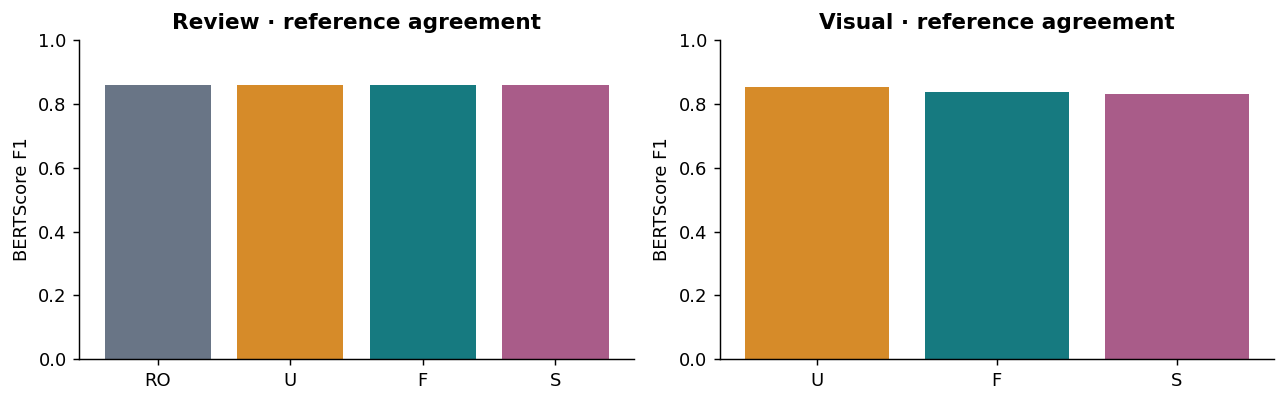

In [10]:
auto_paired = pd.DataFrame(load('test100_paired.json'))
primary = auto_paired[auto_paired.metric.eq('bertscore_f1')].copy()
primary['CI_low'] = primary.CI95.map(lambda x:x[0]); primary['CI_high'] = primary.CI95.map(lambda x:x[1])
for _, r in primary.iterrows():
    pivot = test[test.task.eq(r.task)].pivot(index='business_id',columns='condition',values=r.metric)
    comp = r.contrast.split('-')[1]
    assert np.isclose((pivot.F-pivot[comp]).mean(),r.mean_difference,atol=1e-12,rtol=0)
display(primary[['task','contrast','mean_difference','CI_low','CI_high','signflip_two_sided_p','holm_p_four_prespecified_tests']].round(6))
fig, axes = plt.subplots(1,2,figsize=(10,3.2))
for ax, task in zip(axes,['review','visual']):
    part = test_aggregate[test_aggregate.task.eq(task)]
    ax.bar(part.condition,part.bertscore_f1,color=[COLORS[c] for c in part.condition])
    ax.set(title=task.title()+' · reference agreement',ylabel='BERTScore F1',ylim=(0,1))
plt.tight_layout(); plt.show()

words  repeated_3gram_fraction  duplicate_sentence_fraction
condition task                                                               
F         review  86.72                 0.039527                     0.000000
          visual  51.68                 0.060546                     0.003198
RO        review  87.09                 0.031442                     0.000000
S         review  86.72                 0.039527                     0.000000
          visual  51.68                 0.060546                     0.003198
U         review  84.90                 0.034570                     0.000000
          visual  67.74                 0.122986                     0.018732

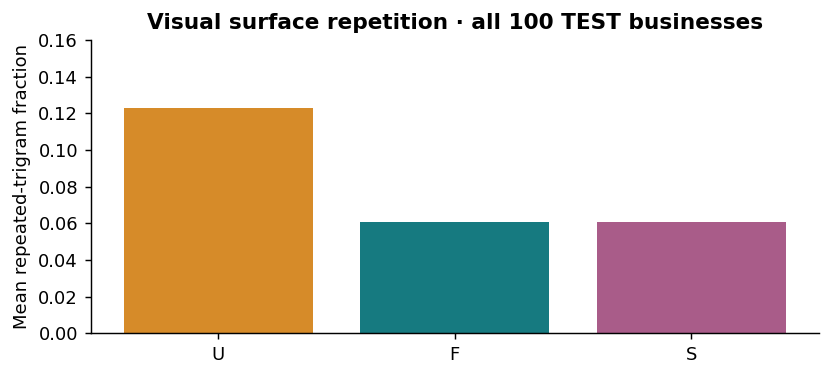

F has less **Visual** repetition than U. This is a surface diagnostic, not proof of factuality. F/S have the same Visual output multiset under permutation, hence the same global repetition; recipient grounding differs. The Review repetition table does not support a blanket claim that F reduces repetition in every component.

**Original implementation:** `scripts/stage_m_evaluation_v1.py`; lines [[89, 123]]. Source-file SHA-256: `43eb40a626e24cff4ba1cd71940f98064ec39deeeb6412688f26769efb605766`. Display only; not executed here.

def score_components(raw,calls,references,scorer,track):
    require(track in TRACK_NAMES,'Reference track')
    rows=[];pairs={}
    for r in raw:
        key=r['condition'],r['business_id'],r['task'];c=calls[key];ref=references[r['business_id']]
        candidate=strip_header(r['text'],r['task']);target=ref['review_consensus' if r['task']=='review' else 'visual_evidence']
        require(isinstance(target,str),'Reference component must be text, not a missing field')
        encode=lambda text:scorer._tokenizer.encode(text.strip(),add_special_tokens=True,add_prefix_space=True,truncation=False)
        cl,rl=len(encode(candidate)),len(encode(target));pair=(candidate,target)
        if pair not in pairs:pairs[pair]=len(pairs)
        expected='[REVIEW_CONSENSUS]\n' if r['task']=='review' else '[VISUAL_EVIDENCE]\n'
        foreign='[VISUAL_EVIDENCE]' if r['task']=='review' else '[REVIEW_CONSENSUS]'
        rows.append({'condition':r['condition'],'business_id':r['business_id'],'reference_business_id':r['business_id'],'task':r['task'],'reference_type':TRACK_NAMES[track],
            'output_sha256':r['text_sha256'],'reference_sha256':ref['reference_sha256'],'source_sha256':r['source_sha256'],'checkpoint_sha256':r['checkpoint_sha256'],
            'empty_candidate':not bool(candidate.strip()),'empty_reference':not bool(target.strip()),'malformed_header':not r['text'].startswith(expected),
            'foreign_component_marker':foreign in r['text'],'at_generation_cap':len(r['token_ids'])>=768,
            'bert_candidate_tokens_untruncated':cl,'bert_reference_tokens_untruncated':rl,'bert_candidate_prefix_truncated':cl>512,'bert_reference_prefix_truncated':rl>512,
            **descriptive_score(candidate,target,c['source']),'_pair':pair})
    # Cache by BOTH candidate and recipient reference, never by donor output alone.
    # This preserves exact F/S Review equality instead of separate padded batches.
    nonempty=[pair for pair in pairs if pair[0].strip() and pair[1].strip()];scores={pair:(0.,0.,0.) for pair in pairs}
    if nonempty:
        import torch
        with torch.no_grad():p,r,f=scorer.score([x[0] for x in nonempty],[x[1] for x in nonempty],batch_size=8,verbose=False)
        for i,pair in enumerate(nonempty):scores[pair]=(float(p[i]),float(r[i]),float(f[i]))
    for row in rows:
        pair=row.pop('_pair');p,r,f=scores[pair];require(all(math.isfinite(x) for x in [p,r,f]),'Nonfinite BERTScore')
        row.update(bertscore_precision=p,bertscore_recall=r,bertscore_f1=f)
    by={(r['condition'],r['business_id'],r['task']):r for r in rows}
    for b in references:
        if ('F',b,'review') in by and ('S',b,'review') in by:
            require(all(by['F',b,'review'][m]==by['S',b,'review'][m] for m in METRICS),'F/S Review scores differ')
    return rows,{'unique_candidate_reference_pairs':len(pairs),'nonempty_pairs_forwarded':len(nonempty),
        'empty_policy':'If either component is empty, ROUGE and BERTScore P/R/F are zero, including both-empty; retain every business.',
        'pair_cache':'Exact candidate text + recipient reference text; no donor-reference lookup','F_S_review_scores_identical':True}

In [11]:
surface = test.groupby(['condition','task'])[['words','repeated_3gram_fraction','duplicate_sentence_fraction']].mean()
display(surface.round(6))
fig, ax = plt.subplots(figsize=(6.5,3))
v = surface.xs('visual',level='task').reindex(['U','F','S'])
ax.bar(v.index,v.repeated_3gram_fraction,color=[COLORS[c] for c in v.index])
ax.set(ylabel='Mean repeated-trigram fraction',title='Visual surface repetition · all 100 TEST businesses',ylim=(0,.16))
plt.tight_layout(); plt.show()
display(Markdown('F has less **Visual** repetition than U. This is a surface diagnostic, not proof of factuality. '
    'F/S have the same Visual output multiset under permutation, hence the same global repetition; recipient grounding differs. '
    'The Review repetition table does not support a blanket claim that F reduces repetition in every component.'))
implementation('metric_scoring')

## 9. TEST30 human evaluation: two evaluators, 240 records
The frozen subset has 30 businesses × 4 outputs × 2 evaluators. Ratings are 1–5, higher better.
Review Faithfulness, Aspect Coverage and Usefulness concern Review; Coherence and Non-Redundancy
concern all available components; Visual Grounding and Contribution concerns Visual and is
structurally N/A for RO. Do not turn N/A into zero or aggregate unrelated criteria into a new score.

For inference, both raters are averaged **within business** before comparing conditions: n=30
business pairs, not 240 independent observations. The accepted human analysis is exploratory:
20,000 bootstrap draws, 50,000 sign flips, common business resampling, seed 20261028, pointwise
95% CIs, **no prespecified multiplicity adjustment**. Raw p-values are not a confirmatory winner test.

condition,RO,U,F,S
Criterion,,,,
review_faithfulness,4.150,4.233,4.033,4.017
aspect_coverage,3.383,3.383,3.083,3.050
coherence,4.550,3.950,4.067,3.700
non_redundancy,3.950,3.117,3.367,3.083
usefulness,3.283,3.283,3.050,3.017
visual_grounding_and_contribution,NaN,4.000,3.900,1.233


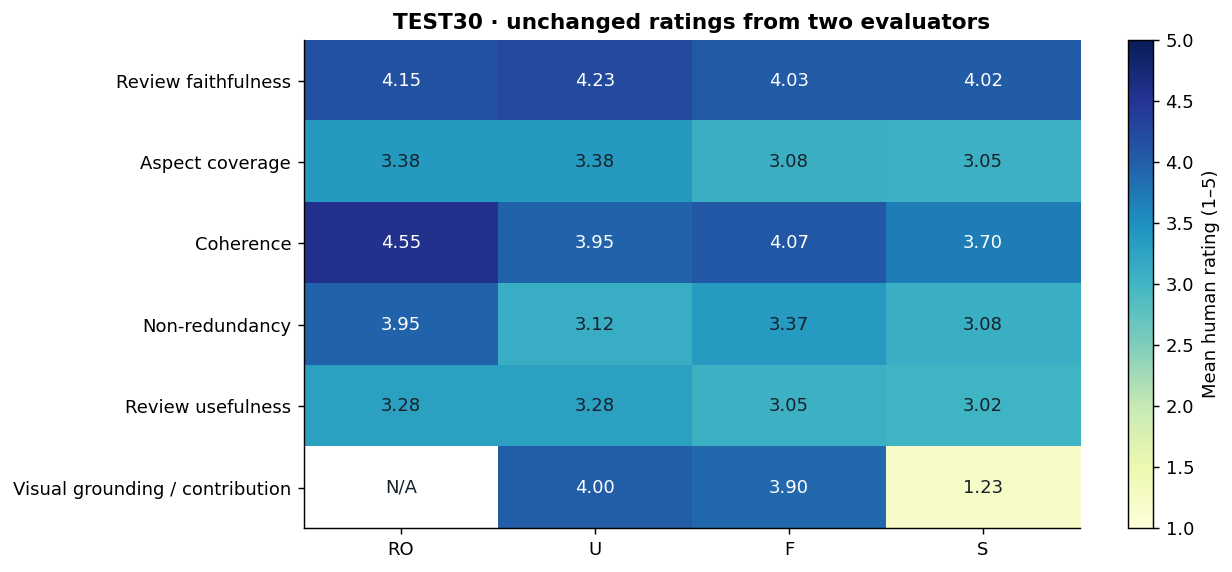

PASS: 240 records, 690 applicable paired-business criterion rows and all combined means agree.


In [12]:
ratings = pd.DataFrame(load('test30_ratings_240.json'))
human_per = table('test30_per_business_criterion.csv')
human_desc = table('test30_descriptive.csv')
criteria = ['review_faithfulness','aspect_coverage','coherence','non_redundancy','usefulness','visual_grounding_and_contribution']
# Preserve structural 'N/A' in the raw export; convert only in this in-memory numeric view.
assert ratings.loc[ratings.condition.eq('RO'),'visual_grounding_and_contribution'].eq('N/A').all()
ratings[criteria] = ratings[criteria].where(ratings[criteria].ne('N/A')).astype(float)
assert len(ratings) == 240 and ratings.business_id.nunique() == 30
assert not ratings.duplicated(['business_id','condition','annotator']).any()
assert ratings.groupby(['annotator','condition']).size().eq(30).all()
assert set(ratings.business_id) <= set(test.business_id)
assert ratings.loc[ratings.condition.eq('RO'),'visual_grounding_and_contribution'].isna().all()
observed = ratings.groupby('condition')[criteria].mean().reindex(ORDER)
for _, r in human_desc[human_desc.panel.eq('COMBINED')].iterrows():
    actual = observed.loc[r.condition,r.criterion]
    assert (pd.isna(actual) and pd.isna(r['mean'])) or np.isclose(actual,r['mean'],atol=1e-12,rtol=0)
for _, r in human_per.iterrows():
    pair = ratings[ratings.business_id.eq(r.business_id) & ratings.condition.eq(r.condition)][r.criterion]
    assert len(pair) == 2 and np.isclose(pair.mean(),r.two_rater_average,atol=1e-12,rtol=0)
display(observed.T.round(3).rename_axis('Criterion'))
fig, ax = plt.subplots(figsize=(10,4.5))
im = ax.imshow(observed.T, vmin=1,vmax=5,cmap='YlGnBu',aspect='auto')
ax.set_xticks(range(4),ORDER)
ax.set_yticks(range(6),['Review faithfulness','Aspect coverage','Coherence','Non-redundancy','Review usefulness','Visual grounding / contribution'])
for i in range(6):
    for j in range(4):
        x=observed.T.iloc[i,j]; ax.text(j,i,'N/A' if pd.isna(x) else f'{x:.2f}',ha='center',va='center',color='white' if x>3.6 else '#17212b')
fig.colorbar(im,ax=ax,label='Mean human rating (1–5)'); ax.set_title('TEST30 · unchanged ratings from two evaluators')
plt.tight_layout(); plt.show()
print('PASS: 240 records, 690 applicable paired-business criterion rows and all combined means agree.')

,criterion,contrast,n_businesses,mean_paired_difference,CI95_low,CI95_high,unadjusted_exploratory_signflip_p
0,review_faithfulness,F-RO,30,-0.116667,-0.416667,0.183333,0.531489
1,review_faithfulness,F-U,30,-0.200000,-0.600000,0.183333,0.389372
2,review_faithfulness,F-S,30,0.016667,-0.050000,0.100000,1.000000
3,aspect_coverage,F-RO,30,-0.300000,-0.566667,-0.083333,0.017500
4,aspect_coverage,F-U,30,-0.300000,-0.500000,-0.133333,0.003300
5,aspect_coverage,F-S,30,0.033333,0.000000,0.083333,0.499630
6,coherence,F-RO,30,-0.483333,-0.866667,-0.133333,0.013780
7,coherence,F-U,30,0.116667,-0.183333,0.400000,0.524610
8,coherence,F-S,30,0.366667,0.166667,0.566667,0.002120
9,non_redundancy,F-RO,30,-0.583333,-1.050000,-0.133333,0.024060


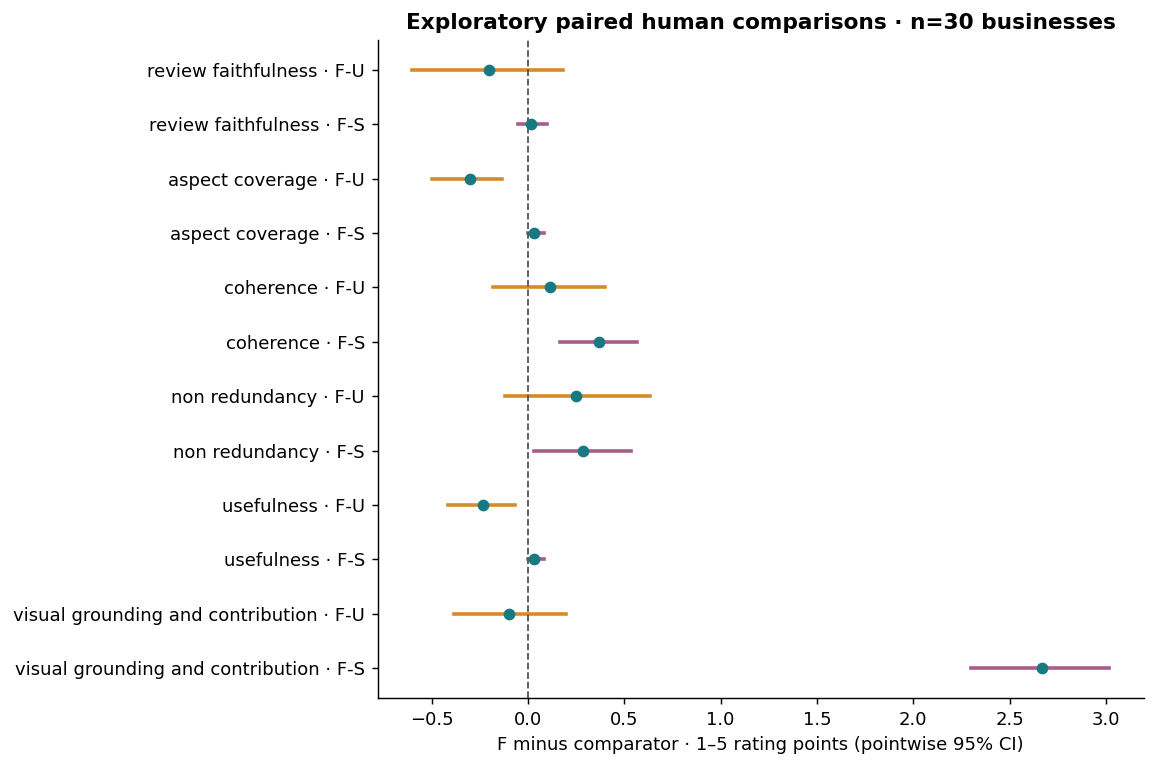

In [13]:
human_paired = pd.DataFrame(load('test30_paired.json'))
for _, r in human_paired.iterrows():
    p = human_per[human_per.criterion.eq(r.criterion)].pivot(index='business_id',columns='condition',values='two_rater_average')
    assert np.isclose((p.F-p[r.contrast.split('-')[1]]).mean(),r.mean_paired_difference,atol=1e-12,rtol=0)
display(human_paired[['criterion','contrast','n_businesses','mean_paired_difference','CI95_low','CI95_high','unadjusted_exploratory_signflip_p']].round(6))
part = human_paired[human_paired.contrast.isin(['F-U','F-S'])].copy().iloc[::-1]
fig, ax = plt.subplots(figsize=(9,6))
for y, (_,r) in enumerate(part.iterrows()):
    ax.plot([r.CI95_low,r.CI95_high],[y,y],color=COLORS[r.contrast.split('-')[1]],lw=2)
    ax.scatter(r.mean_paired_difference,y,color=COLORS['F'],s=30,zorder=3)
ax.axvline(0,color='#555',ls='--',lw=1)
ax.set_yticks(range(len(part)),[r.criterion.replace('_',' ')+' · '+r.contrast for _,r in part.iterrows()])
ax.set(xlabel='F minus comparator · 1–5 rating points (pointwise 95% CI)',title='Exploratory paired human comparisons · n=30 businesses')
plt.tight_layout(); plt.show()

### Agreement and measurement limitations
Fixed 1–5 quadratic-weighted Cohen kappa is reported per condition and criterion (30 pairs).
Pooled agreement is supplementary because mixing easy and hard conditions can inflate it. There
are only two evaluators; these intervals do not generalize over a sampled population of raters.
F and S reuse exactly the same Review generation. Six of 180 Review-only repeated-rating pairs
differ, illustrating rating/context variability rather than a Review model improvement.
Recorded roles and participant declarations do not independently authenticate identity, source
inspection or independence. Accepted ratings are retained without manufacturing corrections.

In [14]:
implementation('quadratic_kappa')
# Execute only this self-contained, original statistics helper, not its live-application imports.
from collections import Counter
scope = {'Counter': Counter}
exec((BASE / 'code/quadratic_kappa.txt').read_text(encoding='utf-8'),scope)
agreement = table('test30_agreement.csv')
display(agreement.head(10))
for condition in ORDER:
    for criterion in criteria:
        if condition == 'RO' and criterion == 'visual_grounding_and_contribution': continue
        pairs = ratings[ratings.condition.eq(condition)].pivot(index='business_id',columns='annotator',values=criterion)
        k = scope['kappa_quadratic'](pairs.A01.astype(int).tolist(), pairs.A02.astype(int).tolist())['value']
        original = agreement[agreement.condition.eq(condition) & agreement.criterion.eq(criterion)].iloc[0].qwk
        assert (k is None and pd.isna(original)) or np.isclose(k,original,atol=1e-12,rtol=0)
print('PASS: all 23 applicable kappa panels reproduce the original agreement table.')

**Original implementation:** `scripts/analyze_stage_n_two_raters_v1.py`; lines [[10, 21]]. Source-file SHA-256: `18bda30753c0ab863daf6c2caa1f239af160a6a4b31aea373706168ed88241d6`. Display only; not executed here.

def kappa_quadratic(x,y):
    """Fixed categories 1..5, weights (i-j)^2/16; Cohen 1-Do/De.

    Primary reference: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.cohen_kappa_score.html
    Missing pairs are not imputed. Caller uses complete records only.
    """
    if not x or len(x)!=len(y):return {'value':None,'reason':'No complete paired ratings','n':0}
    if any(type(v) is not int or not 1<=v<=5 for v in x+y):raise ValueError('Scores must be integers 1-5')
    n=len(x);a=Counter(x);b=Counter(y)
    observed=sum((u-v)**2 for u,v in zip(x,y))/n
    expected=sum(a[i]*b[j]*(i-j)**2 for i in range(1,6) for j in range(1,6))/(n*n)
    return {'value':1-observed/expected if expected else None,'reason':None if expected else 'Undefined: zero expected disagreement (constant category)', 'n':n,'fixed_categories':[1,2,3,4,5]}

,condition,criterion,n_paired_items,n_unique_businesses,qwk,undefined_reason,exact_n,exact_agreement_pct,...,difference_-3,difference_-2,difference_-1,difference_0,difference_1,difference_2,difference_3,difference_4
0,RO,review_faithfulness,30,30,0.854054,NaN,21,70.000000,...,0,0,5,21,4,0,0,0
1,RO,aspect_coverage,30,30,0.684685,NaN,23,76.666667,...,0,0,3,23,4,0,0,0
2,RO,coherence,30,30,0.635762,NaN,19,63.333333,...,0,0,10,19,1,0,0,0
3,RO,non_redundancy,30,30,0.862104,NaN,24,80.000000,...,0,0,1,24,4,1,0,0
4,RO,usefulness,30,30,0.628099,NaN,21,70.000000,...,0,0,5,21,4,0,0,0
5,U,review_faithfulness,30,30,0.886792,NaN,24,80.000000,...,0,0,5,24,1,0,0,0
6,U,aspect_coverage,30,30,0.851485,NaN,27,90.000000,...,0,0,2,27,1,0,0,0
7,U,coherence,30,30,0.578834,NaN,17,56.666667,...,0,0,12,17,1,0,0,0
8,U,non_redundancy,30,30,0.747736,NaN,20,66.666667,...,0,0,1,20,8,1,0,0
9,U,usefulness,30,30,0.684685,NaN,23,76.666667,...,0,0,4,23,3,0,0,0


PASS: all 23 applicable kappa panels reproduce the original agreement table.


## 10. Complete generated-summary examples
Three deliberately illustrative cases are retained: the first frozen TEST case, a pub case and the
known generation-cap failure. These are not a new qualitative sample. Model outputs and frozen
reference summaries are unmodified, with their original hashes. BLIP-2 captions are model-generated
derived evidence. Original review text and photo pixels are withheld from this public edition;
the private research archive retains them unchanged. No factuality re-audit is claimed here.

In [15]:
cases = load('illustrative_cases.json')
for example in cases:
    case=example['case']
    display(Markdown('### '+case['business_name']+' · `'+case['business_id']+'`' + chr(10) + example['selection_reason']))
    def detail(label, text, opened=False):
        return ('<details open>' if opened else '<details>')+'<summary>'+html.escape(label)+'</summary><pre style="white-space:pre-wrap;max-height:400px;overflow:auto">'+html.escape(text)+'</pre></details>'
    sections=[]
    for c in ORDER:
        for task in ['review','visual']:
            item=case['models'][c][task]
            if item:
                assert hashlib.sha256(item['raw_output_text'].encode()).hexdigest() == item['output_sha256']
                sections.append(detail(c+' · '+task+' · original output',item['raw_output_text'],c=='F' and case['business_id']!='ymE6ka6y6J-z2y2rX8QH3Q'))
    for condition,captions in example['captions'].items():
        sections.append(detail(condition+' · exact BLIP-2 captions',json.dumps(captions,ensure_ascii=False,indent=2)))
    sections.append(detail('Source review identifiers (original text withheld)',json.dumps(example['source_review_ids'],ensure_ascii=False,indent=2)))
    sections.append(detail('Frozen final reference (comparison aid, not unquestionable truth)',json.dumps(case['reference'],ensure_ascii=False,indent=2)))
    display(HTML(''.join(sections)))

### Mungo's Italian Eatery · `-78Va3llKcPbL6SW4is8lw`
First TEST business in frozen order; illustrates generic Review and caption-limited Visual output.

### Highlander Pub & Grill · `zGmK4tkN9X_wBi_9i1jIuw`
Illustrative pub case; compare U/F/S source alignment without treating one example as aggregate proof.

### Capriotti's Sandwich Shop · `ymE6ka6y6J-z2y2rX8QH3Q`
Known generation-cap repetition case, retained as a failure example rather than silently repaired.

## 11. External TripAdvisor generalization — Stage O
The frozen Yelp-trained RO/U/F checkpoints were applied without further fine-tuning to
**15 restaurants**, 247 selected reviews and 5,143 source photos. The evaluation has two
accounts and **90 submitted records**. It is reference-free source-grounded rating, not
agreement with Teacher answers. RO Visual is structurally N/A, never a zero-quality output.

The paired unit is the restaurant: average the two within-rater differences, retaining both
raters together. The frozen exploratory policy uses 20,000 bootstrap draws, 50,000 sign flips,
seed 20261028, pointwise 95% intervals and no prespecified multiplicity correction. The 11
contrasts include two supplementary output-budget-confounded F–RO comparisons. Do not pool
these ratings with Yelp or with the later Stage P session.

model,RO,U,F
criterion,,,
Review faithfulness,3.500,3.500,3.700
Aspect coverage,3.200,3.267,3.233
Coherence,4.433,4.000,4.167
Non-redundancy,4.200,3.000,3.833
Review usefulness,2.900,2.933,3.033
Visual grounding / contribution,NaN,3.700,3.533


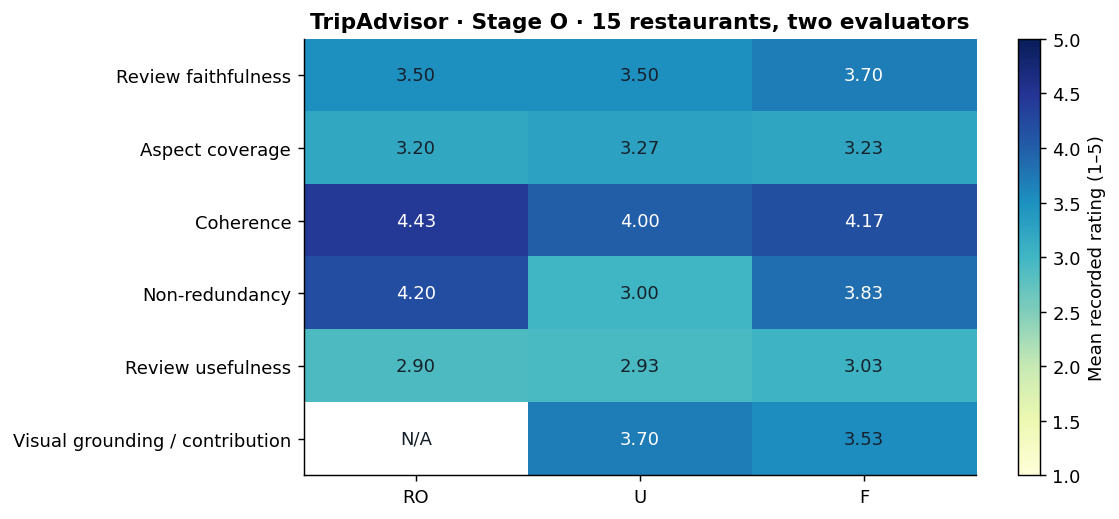

,model,criterion,panel,n,mean,sample_SD,median
0,RO,review_faithfulness,COMBINED,30,3.500,1.137,3.0
1,RO,review_faithfulness,A01,15,3.333,1.291,3.0
2,RO,review_faithfulness,A02,15,3.667,0.976,3.0
3,U,review_faithfulness,COMBINED,30,3.500,1.306,3.0
4,U,review_faithfulness,A01,15,3.467,1.506,3.0
5,U,review_faithfulness,A02,15,3.533,1.125,3.0
6,F,review_faithfulness,COMBINED,30,3.700,1.088,4.0
7,F,review_faithfulness,A01,15,3.533,1.246,4.0
8,F,review_faithfulness,A02,15,3.867,0.915,4.0
9,RO,aspect_coverage,COMBINED,30,3.200,0.407,3.0


In [16]:
o_rows = external_records(BASE, 'O')
o_desc = pd.DataFrame(load('final/O_DESCRIPTIVES.json'))
o_agreement = pd.DataFrame(load('final/O_AGREEMENT.json'))
labels = ['Review faithfulness','Aspect coverage','Coherence','Non-redundancy',
          'Review usefulness','Visual grounding / contribution']
def human_panel(desc, order, title):
    matrix = desc[desc.panel.eq('COMBINED')].pivot(index='criterion',columns='model',values='mean').reindex(index=criteria,columns=order)
    display(matrix.rename(index=dict(zip(criteria,labels))).round(3))
    fig, ax = plt.subplots(figsize=(9,4.1))
    image = ax.imshow(matrix, vmin=1, vmax=5, cmap='YlGnBu', aspect='auto')
    ax.set_xticks(range(len(order)), order)
    ax.set_yticks(range(6), labels)
    for i in range(6):
        for j in range(len(order)):
            v = matrix.iloc[i,j]
            ax.text(j,i,'N/A' if pd.isna(v) else f'{v:.2f}',ha='center',va='center',
                    color='white' if pd.notna(v) and v>3.6 else '#17212b')
    ax.set_title(title)
    fig.colorbar(image,ax=ax,label='Mean recorded rating (1–5)')
    plt.tight_layout(); plt.show()
human_panel(o_desc, ['RO','U','F'], 'TripAdvisor · Stage O · 15 restaurants, two evaluators')
display(o_desc[['model','criterion','panel','n','mean','sample_SD','median']].round(3))

,contrast,criterion,scope,n_businesses,mean_difference,CI95_low,CI95_high,raw_signflip_p
0,F-RO,review_faithfulness,FROZEN_EXPLORATORY_PLAN,15,0.200000,-0.233333,0.666667,0.488750
1,F-U,review_faithfulness,FROZEN_EXPLORATORY_PLAN,15,0.200000,-0.200000,0.566667,0.420472
2,F-RO,aspect_coverage,FROZEN_EXPLORATORY_PLAN,15,0.033333,-0.133333,0.233333,1.000000
3,F-U,aspect_coverage,FROZEN_EXPLORATORY_PLAN,15,-0.033333,-0.233333,0.200000,1.000000
4,F-RO,coherence,SUPPLEMENTARY_COMPONENT_BUDGET_DIFFERENCE,15,-0.266667,-0.566667,0.066667,0.189176
5,F-U,coherence,FROZEN_EXPLORATORY_PLAN,15,0.166667,0.000000,0.333333,0.185716
6,F-RO,non_redundancy,SUPPLEMENTARY_COMPONENT_BUDGET_DIFFERENCE,15,-0.366667,-0.700000,0.033333,0.118998
7,F-U,non_redundancy,FROZEN_EXPLORATORY_PLAN,15,0.833333,0.400000,1.333333,0.004740
8,F-RO,usefulness,FROZEN_EXPLORATORY_PLAN,15,0.133333,0.000000,0.300000,0.248375
9,F-U,usefulness,FROZEN_EXPLORATORY_PLAN,15,0.100000,-0.133333,0.333333,0.627687


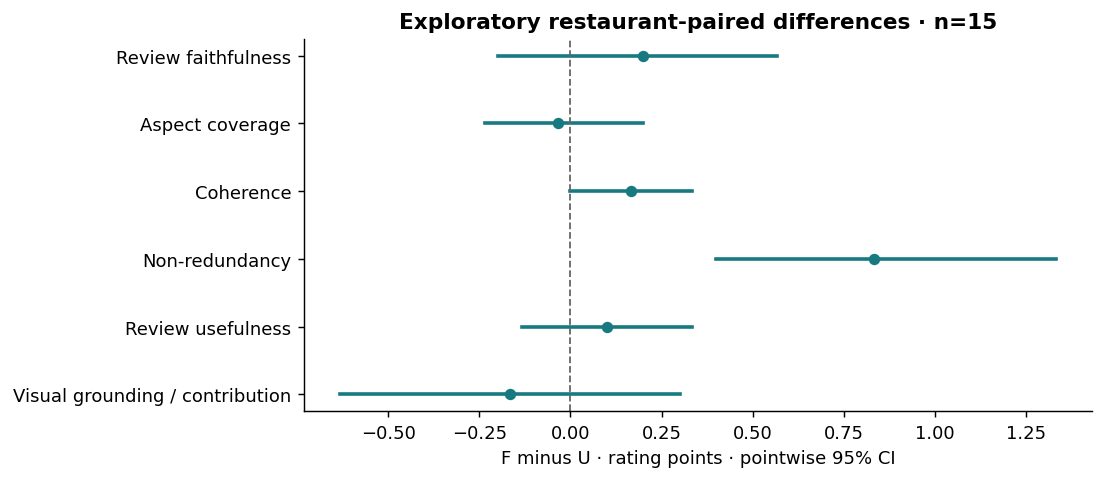

,model,criterion,quadratic_weighted_kappa,exact_agreement_fraction,mean_absolute_difference
0,RO,review_faithfulness,0.870,0.667,0.333
1,U,review_faithfulness,0.859,0.533,0.467
2,F,review_faithfulness,0.687,0.467,0.600
3,RO,aspect_coverage,0.167,0.733,0.267
4,U,aspect_coverage,0.375,0.733,0.267
5,F,aspect_coverage,0.815,0.933,0.067
6,RO,coherence,0.590,0.667,0.333
7,U,coherence,0.388,0.733,0.267
8,F,coherence,0.000,0.667,0.333
9,RO,non_redundancy,0.904,0.867,0.133


In [17]:
o_paired = pd.DataFrame(load('final/O_PAIRED_COMPARISONS.json'))
display(o_paired[['contrast','criterion','scope','n_businesses','mean_difference',
                  'CI95_low','CI95_high','raw_signflip_p']].round(6))
part = o_paired[o_paired.contrast.eq('F-U')].set_index('criterion').reindex(criteria)
fig, ax = plt.subplots(figsize=(8.6,3.8))
for i,(criterion,r) in enumerate(part.iterrows()):
    ax.plot([r.CI95_low,r.CI95_high],[i,i],color=COLORS['F'],lw=2)
    ax.scatter(r.mean_difference,i,color=COLORS['F'],s=28)
ax.axvline(0,color='#666',ls='--',lw=1)
ax.set_yticks(range(6),labels); ax.invert_yaxis()
ax.set(xlabel='F minus U · rating points · pointwise 95% CI',title='Exploratory restaurant-paired differences · n=15')
plt.tight_layout(); plt.show()
display(o_agreement[['model','criterion','quadratic_weighted_kappa',
                     'exact_agreement_fraction','mean_absolute_difference']].round(3))

## 12. Qwen baseline — Stage P, official original V1
**Qwen/Qwen3.5-9B**, pretrained instruction-following, BF16, batch 1, thinking disabled,
greedy decoding; no task fine-tuning or GPT Teacher supervision. The primary caption-text
comparison reuses exactly LED F's selected reviews/Filtered captions in separate evidence
passes. Review receives reviews; Visual receives captions. The Image extension replaces the
Visual input with the corresponding **73 selected photos**, while reusing the 15 Qwen Review
generations. Image selection itself inherits the BLIP/filter pipeline.

This compares complete pretrained/task-tuned systems, not architecture or parameter count
in isolation. Prompts, decoding, output scope and tuning differ. Qwen Review averages 132.87
words versus LED's 81.07. Longer scope can change coverage. Original outputs are retained.

The official original V1 archive SHA-256 is
`e2f3715d522f1d9505075f2f79c0d394880cc9dbb8462579b99c41ca82f28fc5`.
Only its **90 records**, 15 restaurants × three systems × two evaluators, are used here.
Later rating revisions are excluded. Labels are restored using the frozen alias mapping.

In [18]:
qspec = json.loads((BASE/'evidence/P/QWEN_CAPTION_FROZEN_SPEC.json').read_text(encoding='utf-8'))
alignment = json.loads((BASE/'evidence/P/QWEN_INPUT_ALIGNMENT.json').read_text(encoding='utf-8'))
assert alignment['status'] == 'PASS' and len(alignment['checks']) == 30
assert all(r['exact_source_equal'] and r['evidence_IDs_equal'] for r in alignment['checks'])
display(pd.Series({'model':qspec['models']['Qwen3.5-9B']['model_id'],
                   'revision':qspec['models']['Qwen3.5-9B']['revision'],
                   'precision':qspec['precision'],'thinking':qspec['enable_thinking'],
                   'generation':qspec['generation'],
                   'input_hash':qspec['input_sha256'],'prompt_hash':qspec['prompts_sha256']},name='Frozen specification').to_frame())
print('The original planning receipt retains PENDING metadata; completed output/mapping and runtime evidence establish execution. Its fallback option was not used.')
implementation('qwen_frozen_inference')

,Frozen specification
model,Qwen/Qwen3.5-9B
revision,c202236235762e1c871ad0ccb60c8ee5ba337b9a
precision,bfloat16
thinking,False
generation,"{'do_sample': False, 'num_beams': 1, 'repetition_penalty': 1.0, 'use_cache': True, 'ma..."
input_hash,155cd3e329514e631e9171417a0b0aad7fcb9f07a1c76104b34700d90eeb5cb8
prompt_hash,9ac4f965a3c73e6c4cdbed777ac76104a8bdb9b631d957c83b8d7b82e9efb04d


The original planning receipt retains PENDING metadata; completed output/mapping and runtime evidence establish execution. Its fallback option was not used.


**Original implementation:** `scripts/stage_p_qwen_bf16_3090_v2.py`; lines [[33, 44], [126, 145]]. Source-file SHA-256: `914a9028c9fccb47f73136a0a0dfd61aa96458581c645952194f3746f63396aa`. Display only; not executed here.

def render(root,spec,prompts,rows):
    from transformers import AutoTokenizer
    folder=root/'MODEL_PROVENANCE/TOKENIZERS'/MODEL
    for file,h in spec['models'][MODEL]['tokenizer_files'].items():need(sha(folder/file)==h,'Frozen tokenizer changed')
    tok=AutoTokenizer.from_pretrained(folder,local_files_only=True,trust_remote_code=False);calls=[]
    for r in rows:
        messages=[dict(role='system',content=prompts[r['task']]),dict(role='user',content=r['source'])]
        text=tok.apply_chat_template(messages,tokenize=False,add_generation_prompt=True,enable_thinking=False)
        need(r['source'] in text and text.endswith('<think>\n\n</think>\n\n'),'Non-thinking template/source check failed')
        ids=tok.encode(text,add_special_tokens=False);need(len(ids)<=spec['max_input_tokens'],'Input too long: no truncation allowed')
        calls.append(dict(call_id=r['call_id'],business_id=r['business_id'],task=r['task'],input_ids=ids,input_ids_sha256=ids_sha(ids),rendered_prompt_sha256=textsha(text),input_tokens=len(ids),source_sha256=r['source_sha256']))
    return tok,calls

        model=Qwen3_5ForConditionalGeneration.from_pretrained(folder,local_files_only=True,trust_remote_code=False,dtype=torch.bfloat16,device_map={'':'cuda:0'},attn_implementation='sdpa').eval()
        torch.cuda.synchronize();load_seconds=time.perf_counter()-t;peaks.append(dict(phase='load',seconds=load_seconds,**memory()))
        need(all(p.device.type=='cuda' and p.device.index in [0,None] for p in model.parameters()),'Unexpected CPU/multi-device offload')
        need(all(p.dtype==torch.bfloat16 for p in model.parameters() if p.is_floating_point()),'Unexpected non-BF16 parameters')
        torch.manual_seed(spec['seed']);torch.cuda.manual_seed_all(spec['seed']);cm={r['call_id']:r for r in calls}
        for index,r in enumerate(order):
            phase='pilot_generation' if index<2 else 'full_generation'
            need(index<2 or (dest/'COMPATIBILITY_PASS.json').exists(),'Full batch before pilot PASS is forbidden')
            rendered=cm[r['call_id']];ids=rendered['input_ids'];torch.cuda.reset_peak_memory_stats();tensor=torch.tensor([ids],device='cuda:0',dtype=torch.long);mask=torch.ones_like(tensor)
            settings={k:v for k,v in spec['generation'].items() if k!='max_new_tokens_by_task'};settings.update(max_new_tokens=spec['generation']['max_new_tokens_by_task'][r['task']],pad_token_id=tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id,eos_token_id=tok.eos_token_id)
            torch.cuda.synchronize();t=time.perf_counter()
            with torch.inference_mode():generated=model.generate(input_ids=tensor,attention_mask=mask,**settings)
            torch.cuda.synchronize();seconds=time.perf_counter()-t;tokens=generated[0,len(ids):].tolist();text=tok.decode(tokens,skip_special_tokens=True);raw=tok.decode(tokens,skip_special_tokens=False);m=memory()
            header='[REVIEW_CONSENSUS]' if r['task']=='review' else '[VISUAL_EVIDENCE]'
            eos=tok.eos_token_id if isinstance(tok.eos_token_id,list) else [tok.eos_token_id]
            flags=dict(empty=not text.strip(),heading_missing=not text.startswith(header),unexpected_thinking=('<think>' in text or '</think>' in text),hit_token_cap=len(tokens)>=settings['max_new_tokens'],stop_token_seen=bool(tokens and tokens[-1] in eos))
            result=dict(**{k:r[k] for k in ['call_id','business_id','task','source_sha256','selected_review_ids','selected_photo_ids']},model_id=mi['model_id'],model_revision=mi['revision'],phase=phase,input_ids=ids,input_ids_sha256=rendered['input_ids_sha256'],rendered_prompt_sha256=rendered['rendered_prompt_sha256'],generation_token_ids=tokens,text=text,raw_decoded_with_special_tokens=raw,text_sha256=textsha(text),input_tokens=len(ids),output_tokens=len(tokens),generation_seconds=seconds,tokens_per_second_including_prefill=len(tokens)/seconds,token_count_includes_stop_and_special_tokens=True,VRAM=m,generation_settings=settings,enable_thinki

model,LED F original,Qwen-Caption,Qwen-Image
criterion,,,
Review faithfulness,3.267,4.300,4.300
Aspect coverage,3.000,4.533,4.533
Coherence,4.067,5.000,5.000
Non-redundancy,3.167,4.800,4.800
Review usefulness,2.933,4.400,4.400
Visual grounding / contribution,3.533,3.533,4.167


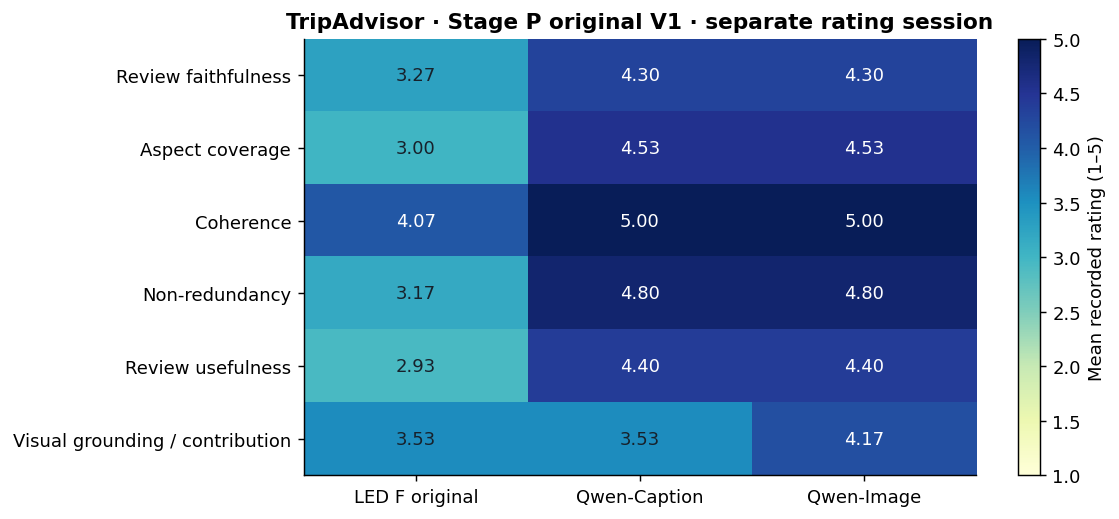

,model,criterion,panel,n,mean,sample_SD,median,score_1,score_2,score_3,score_4,score_5
0,LED F original,review_faithfulness,COMBINED,30,3.267,1.143,3.0,2,5,11,7,5
1,LED F original,review_faithfulness,A01,15,3.333,1.291,3.0,1,3,5,2,4
2,LED F original,review_faithfulness,A02,15,3.200,1.014,3.0,1,2,6,5,1
3,Qwen-Caption,review_faithfulness,COMBINED,30,4.300,0.702,4.0,0,0,4,13,13
4,Qwen-Caption,review_faithfulness,A01,15,4.400,0.737,5.0,0,0,2,5,8
5,Qwen-Caption,review_faithfulness,A02,15,4.200,0.676,4.0,0,0,2,8,5
6,Qwen-Image,review_faithfulness,COMBINED,30,4.300,0.702,4.0,0,0,4,13,13
7,Qwen-Image,review_faithfulness,A01,15,4.400,0.737,5.0,0,0,2,5,8
8,Qwen-Image,review_faithfulness,A02,15,4.200,0.676,4.0,0,0,2,8,5
9,LED F original,aspect_coverage,COMBINED,30,3.000,0.455,3.0,0,3,24,3,0


In [19]:
p_rows = external_records(BASE, 'P')
p_desc = pd.DataFrame(load('final/P_DESCRIPTIVES.json'))
p_order = ['LED F original','Qwen-Caption','Qwen-Image']
human_panel(p_desc, p_order, 'TripAdvisor · Stage P original V1 · separate rating session')
display(p_desc[['model','criterion','panel','n','mean','sample_SD','median',
                'score_1','score_2','score_3','score_4','score_5']].round(3))

### Paired inference and reliability
Both raters remain paired within each restaurant. The frozen seed is 20261106; percentile
bootstrap uses 20,000 restaurant draws and exact sign flips enumerate all 2^15 assignments.
Holm correction is separate for 12 primary and six additional exploratory tests. Intervals
are pointwise, not family-wise simultaneous; tests remain exploratory system comparisons.
Non-significance is not equivalence. Shared Review texts are not independent generations.

PASS: all 18 frozen P point estimates, bootstrap intervals, exact tests and Holm adjustments reproduced.


,left,right,criterion,family,mean_difference,pointwise_CI95_low,pointwise_CI95_high,raw_exact_signflip_p,holm_p_within_family
0,LED F original,Qwen-Caption,review_faithfulness,PRIMARY,-1.033333,-1.466667,-0.566667,0.002197,0.017578
1,Qwen-Caption,Qwen-Image,review_faithfulness,PRIMARY,0.000000,0.000000,0.000000,1.000000,1.000000
2,LED F original,Qwen-Image,review_faithfulness,ADDITIONAL_EXPLORATORY,-1.033333,-1.466667,-0.566667,0.002197,0.004395
3,LED F original,Qwen-Caption,aspect_coverage,PRIMARY,-1.533333,-1.766667,-1.266667,0.000061,0.000732
4,Qwen-Caption,Qwen-Image,aspect_coverage,PRIMARY,0.000000,0.000000,0.000000,1.000000,1.000000
5,LED F original,Qwen-Image,aspect_coverage,ADDITIONAL_EXPLORATORY,-1.533333,-1.766667,-1.266667,0.000061,0.000366
6,LED F original,Qwen-Caption,coherence,PRIMARY,-0.933333,-1.000000,-0.833333,0.000061,0.000732
7,Qwen-Caption,Qwen-Image,coherence,PRIMARY,0.000000,0.000000,0.000000,1.000000,1.000000
8,LED F original,Qwen-Image,coherence,ADDITIONAL_EXPLORATORY,-0.933333,-1.000000,-0.833333,0.000061,0.000366
9,LED F original,Qwen-Caption,non_redundancy,PRIMARY,-1.633333,-2.000000,-1.233333,0.000122,0.001099


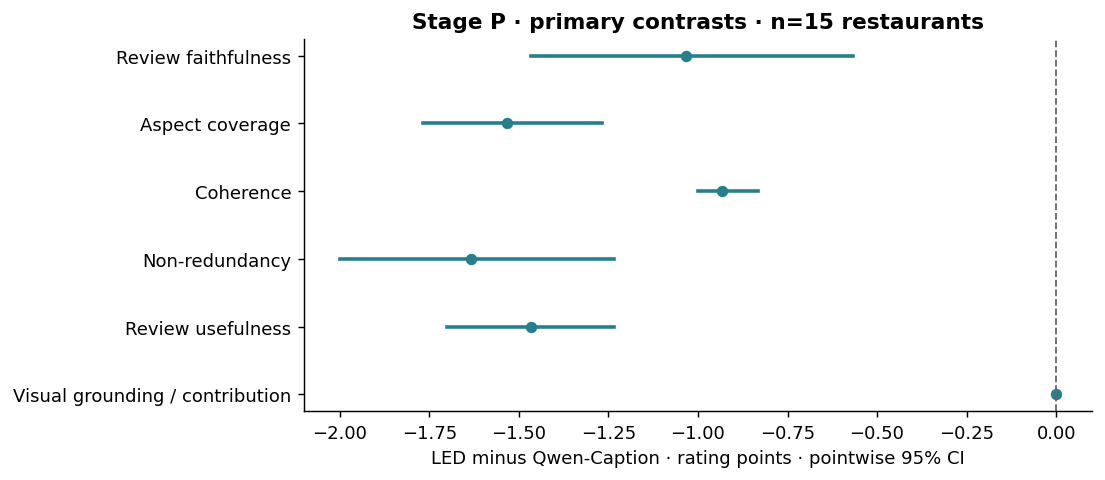

In [20]:
import itertools
p_plan = json.loads((BASE/'evidence/P/ANALYSIS_PLAN.json').read_text(encoding='utf-8'))
p_paired = pd.DataFrame(load('final/P_PAIRED_COMPARISONS.json'))
ids = p_plan['restaurant_order']; raters = p_plan['raters']
cells = {(r['business_id'],r['annotator'],r['model']):r for r in p_rows}
indices = np.random.default_rng(p_plan['seed']).integers(0,15,(p_plan['bootstrap_draws'],15))
assert hashlib.sha256(indices.astype('<i8').tobytes()).hexdigest() == '9a6778bf015ecc2b3180470cb331667800a62205b4cde06405a8b02ff77da393'
signs = np.array(list(itertools.product([-1,1],repeat=15)),dtype=np.int8)
for _,r in p_paired.iterrows():
    d = np.array([np.mean([cells[b,a,r.left][r.criterion]-cells[b,a,r.right][r.criterion] for a in raters]) for b in ids])
    lo,hi = np.quantile(d[indices].mean(axis=1),[.025,.975],method='linear')
    exact_p = np.mean(np.abs((signs*d).mean(axis=1)) >= abs(d.mean())-1e-15)
    assert np.allclose([d.mean(),lo,hi,exact_p],[r.mean_difference,r.pointwise_CI95_low,r.pointwise_CI95_high,r.raw_exact_signflip_p],atol=1e-12,rtol=0)
for family,part in p_paired.groupby('family'):
    ranked=part.sort_values('raw_exact_signflip_p'); running=0
    for j,(_,r) in enumerate(ranked.iterrows()):
        running=max(running,min(1,(len(ranked)-j)*r.raw_exact_signflip_p))
        assert np.isclose(running,r.holm_p_within_family,atol=1e-12,rtol=0)
print('PASS: all 18 frozen P point estimates, bootstrap intervals, exact tests and Holm adjustments reproduced.')
display(p_paired[['left','right','criterion','family','mean_difference','pointwise_CI95_low',
                  'pointwise_CI95_high','raw_exact_signflip_p','holm_p_within_family']].round(6))
part = p_paired[p_paired.left.eq('LED F original') & p_paired.right.eq('Qwen-Caption')].set_index('criterion').reindex(criteria)
fig,ax=plt.subplots(figsize=(8.6,3.8))
for i,(_,r) in enumerate(part.iterrows()):
    ax.plot([r.pointwise_CI95_low,r.pointwise_CI95_high],[i,i],color='#277f8e',lw=2)
    ax.scatter(r.mean_difference,i,color='#277f8e',s=28)
ax.axvline(0,color='#666',ls='--',lw=1);ax.set_yticks(range(6),labels);ax.invert_yaxis()
ax.set(xlabel='LED minus Qwen-Caption · rating points · pointwise 95% CI',title='Stage P · primary contrasts · n=15 restaurants')
plt.tight_layout();plt.show()

In [21]:
p_agreement = pd.DataFrame(load('final/P_AGREEMENT.json'))
display(p_agreement[['model','criterion','quadratic_weighted_kappa','undefined_reason',
                     'exact_agreement_fraction','mean_absolute_difference','mean_first_minus_second']].round(3))
print('Qwen Coherence: all scores are 5; exact agreement is 100%, but QWK is undefined (not 1).')
lengths = pd.DataFrame(load('final/P_OUTPUT_LENGTH_CONTEXT.json'))
display(lengths.round(2))
print('Shared whitespace-word rule; native tokens from different tokenizers are not directly comparable.')
for r in lengths.to_dict('records'):
    outputs=json.loads((BASE/'evidence/P/FROZEN_OUTPUTS_45.json').read_text(encoding='utf-8'))
    values=[]
    marker='[REVIEW_CONSENSUS]' if r['component']=='review' else '[VISUAL_EVIDENCE]'
    for output in outputs:
        if output['system']==r['system']:
            text=output[r['component']+'_text']
            if text.startswith(marker):text=text[len(marker):]
            values.append(len(text.split()))
    assert np.isclose(np.mean(values),r['mean_whitespace_words'],atol=1e-12,rtol=0)

,model,criterion,quadratic_weighted_kappa,undefined_reason,exact_agreement_fraction,mean_absolute_difference,mean_first_minus_second
0,LED F original,review_faithfulness,0.842,None,0.600,0.400,0.133
1,Qwen-Caption,review_faithfulness,0.521,None,0.533,0.467,0.200
2,Qwen-Image,review_faithfulness,0.521,None,0.533,0.467,0.200
3,LED F original,aspect_coverage,0.388,None,0.733,0.267,0.267
4,Qwen-Caption,aspect_coverage,0.302,None,0.467,0.533,0.000
5,Qwen-Image,aspect_coverage,0.302,None,0.467,0.533,0.000
6,LED F original,coherence,0.000,None,0.867,0.133,-0.133
7,Qwen-Caption,coherence,NaN,Both marginal distributions constant at the same score; expected disagreement is zero,1.000,0.000,0.000
8,Qwen-Image,coherence,NaN,Both marginal distributions constant at the same score; expected disagreement is zero,1.000,0.000,0.000
9,LED F original,non_redundancy,0.284,None,0.067,1.400,1.400


Qwen Coherence: all scores are 5; exact agreement is 100%, but QWK is undefined (not 1).


,system,component,n,mean_whitespace_words,minimum,maximum,definition
0,LED F original,review,15,81.07,61,105,Whitespace words after removing one exact leading component marker;descriptive only
1,LED F original,visual,15,69.00,36,88,Whitespace words after removing one exact leading component marker;descriptive only
2,Qwen-Caption,review,15,132.87,119,150,Whitespace words after removing one exact leading component marker;descriptive only
3,Qwen-Caption,visual,15,52.13,41,63,Whitespace words after removing one exact leading component marker;descriptive only
4,Qwen-Image,review,15,132.87,119,150,Whitespace words after removing one exact leading component marker;descriptive only
5,Qwen-Image,visual,15,65.53,50,80,Whitespace words after removing one exact leading component marker;descriptive only


Shared whitespace-word rule; native tokens from different tokenizers are not directly comparable.


## 13. One complete external output example
The first restaurant in sorted ID order is shown deterministically, not selected for quality.
The three frozen Stage P outputs are unmodified and hash-checked. Original review text, photos
and the full source export remain in the private archive; they are not redistributed here.
This display is an output illustration, not an independent source/photo grounding assessment.

In [22]:
selected_id=sorted({r['business_id'] for r in p_rows})[0]
display(Markdown('**External restaurant** · `'+selected_id+'`'))
outputs=json.loads((BASE/'evidence/P/FROZEN_OUTPUTS_45.json').read_text(encoding='utf-8'))
for system in p_order:
    r=next(x for x in outputs if x['business_id']==selected_id and x['system']==system)
    display(Markdown('### '+system))
    for component in ['review','visual']:
        text=r[component+'_text']
        assert hashlib.sha256(text.encode()).hexdigest()==r[component+'_text_sha256']
        display(HTML('<pre style="white-space:pre-wrap">'+html.escape(text)+'</pre>'))
print('Original source reviews and photographs are retained in the restricted archive, not distributed here.')

**External restaurant** · `TA14622324_1001674`

### LED F original

### Qwen-Caption

### Qwen-Image

Original source reviews and photographs are retained in the restricted archive, not distributed here.


## 14. Computational efficiency — measured boundary matters
The prepared-input generation benchmarks use one RTX 3090, with different precision,
decoding, warmups and native token lengths. LED: FP32 weights/FP16 autocast, beam 4, two
measured repeats after warmup. Qwen: BF16, greedy, one run including the cold pilot.
Allocated/reserved memory are PyTorch allocator metrics, not total device usage or minimum
deployment VRAM. Loading is separately recorded and excluded from generation time.

Qwen-Image's 379.697 seconds is an arithmetic sum across sessions: an earlier Review pass
plus the new 242.703-second Visual pass. Its Review was reused. The LED resource replay
matches 22/30 accepted components; its two repeats match each other on 30/30. Evaluators
rated the frozen original outputs, never benchmark replacements. No timing significance
test or exact output-by-output resource/quality equivalence is claimed.

,boundary,seconds,allocated_GiB,reserved_GiB,native_output_tokens,work
0,LED F-S1000,97.931,2.697,3.045,3140,30 calls/repeat; 2 repeats
1,Qwen-Caption,186.844,18.536,18.717,3651,30 calls; one run
2,Qwen-Image constructed,379.697,18.536,18.717,3980,15 earlier Review + 15 new Visual
3,Qwen-Image new Visual only,242.703,17.757,17.820,1342,15 new calls; 73 photos


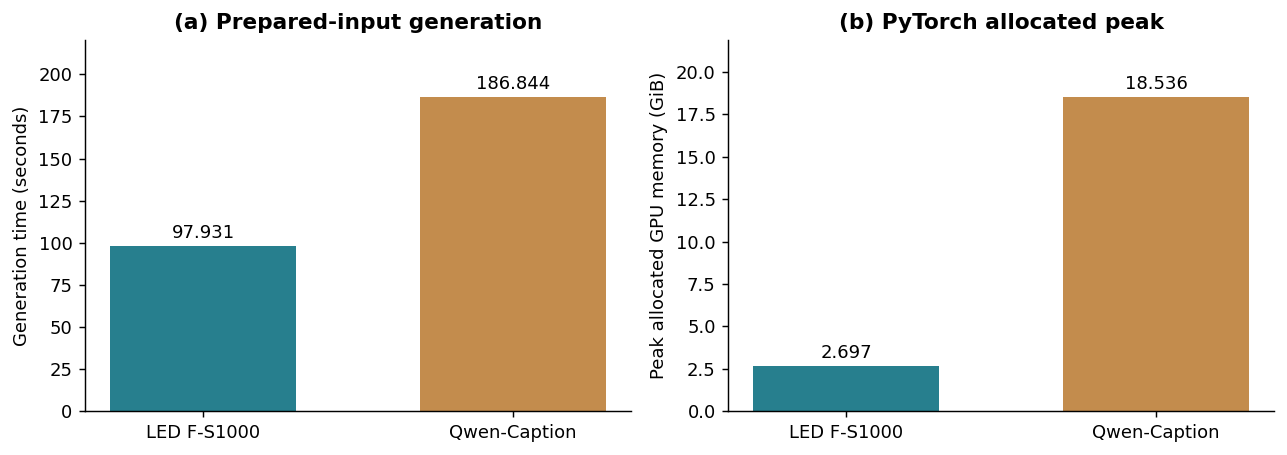

,Separately measured model loading seconds
LED,9.279
Qwen_Caption,11.533
Qwen_Image,5.848


In [23]:
facts=json.loads((BASE/'evidence/EFFICIENCY/VERIFIED_FACTS.json').read_text(encoding='utf-8'))
generation=pd.DataFrame([
  ['LED F-S1000',facts['led_generation_seconds'],facts['led_peak_allocated_GiB'],facts['led_peak_reserved_GiB'],facts['led_tokens'],'30 calls/repeat; 2 repeats'],
  ['Qwen-Caption',facts['qcap_generation_seconds'],facts['qcap_peak_allocated_GiB'],facts['qcap_peak_reserved_GiB'],facts['qcap_tokens'],'30 calls; one run'],
  ['Qwen-Image constructed',facts['qimage_constructed_generation_seconds'],facts['qimage_constructed_peak_allocated_GiB'],facts['qcap_peak_reserved_GiB'],facts['qimage_constructed_tokens'],'15 earlier Review + 15 new Visual'],
  ['Qwen-Image new Visual only',facts['qimage_visual_seconds'],facts['qimage_visual_peak_allocated_GiB'],facts['qimage_visual_peak_reserved_GiB'],facts['qimage_visual_tokens'],'15 new calls; 73 photos']
],columns=['boundary','seconds','allocated_GiB','reserved_GiB','native_output_tokens','work'])
display(generation.round(3))
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
names=['LED F-S1000','Qwen-Caption']; colors=['#277f8e','#c38c4d']
for ax,values,ylabel,title in [
   (axes[0],generation.seconds.iloc[:2],'Generation time (seconds)','(a) Prepared-input generation'),
   (axes[1],generation.allocated_GiB.iloc[:2],'Peak allocated GPU memory (GiB)','(b) PyTorch allocated peak')]:
    ax.bar(names,values,color=colors,width=.6)
    for i,v in enumerate(values):ax.text(i,v+max(values)*.025,f'{v:.3f}',ha='center')
    ax.set(ylabel=ylabel,title=title,ylim=(0,max(values)*1.18))
plt.tight_layout();plt.show()
resource=json.loads((BASE/'evidence/P/RESOURCE_SUMMARY.json').read_text(encoding='utf-8'))
display(pd.Series(resource['load_seconds'],name='Separately measured model loading seconds').to_frame().round(3))

In [24]:
preparation=pd.DataFrame([
  ['BLIP-2 captions',5143,'RTX 3080; CPU/GPU offload',facts['blip_elapsed_seconds'],'Includes 26.295 s loading; 5,150 attempts'],
  ['CLIP/SBERT scoring',5143,'Historical preparation runtime',facts['scoring_elapsed_seconds'],'Includes loading, hashing, image I/O; not final selection'],
  ['Final relevance/redundancy/diversity selection',None,'Frozen selection exists',None,'NOT MEASURED'],
  ['Complete source-to-summary pipeline',None,'No matched complete interval',None,'NOT MEASURED']
],columns=['stage','photos','hardware_or_boundary','seconds','definition'])
display(preparation.fillna('NOT MEASURED'))
print('Recorded preparation component subtotal:',f"{facts['historical_measured_preparation_subtotal_seconds']:.3f}",'seconds; not a measured end-to-end run.')
print('Recorded sequential LED stage allocated maximum is at least',f"{facts['recorded_sequential_LED_stage_max_GiB']:.3f}",'GiB; not a minimum deployment guarantee.')
display(pd.DataFrame(facts['hypothetical_amortization']).round(3))
print('HYPOTHETICAL amortization only: (known preparation + unknown_once)/N + generation + unknown_request.')
print('All three inherit Filtered photo selection. Processing 5,143 photos and 73 selected photos is not a matched end-to-end comparison.')

,stage,photos,hardware_or_boundary,seconds,definition
0,BLIP-2 captions,5143.0,RTX 3080; CPU/GPU offload,48642.959,"Includes 26.295 s loading; 5,150 attempts"
1,CLIP/SBERT scoring,5143.0,Historical preparation runtime,178.529,"Includes loading, hashing, image I/O; not final selection"
2,Final relevance/redundancy/diversity selection,NOT MEASURED,Frozen selection exists,NOT MEASURED,NOT MEASURED
3,Complete source-to-summary pipeline,NOT MEASURED,No matched complete interval,NOT MEASURED,NOT MEASURED


Recorded preparation component subtotal: 48821.488 seconds; not a measured end-to-end run.
Recorded sequential LED stage allocated maximum is at least 4.168 GiB; not a minimum deployment guarantee.


,hypothetical_full_cohort_requests,measured_prep_components_per_request,LED_known_components_per_request,QCAP_known_components_per_request,QIMAGE_inherited_selection_known_components_per_request
0,1,48821.488,48919.419,49008.332,49201.185
1,10,4882.149,4980.080,5068.993,5261.846
2,100,488.215,586.146,675.059,867.912
3,1000,48.821,146.753,235.665,428.518


HYPOTHETICAL amortization only: (known preparation + unknown_once)/N + generation + unknown_request.
All three inherit Filtered photo selection. Processing 5,143 photos and 73 selected photos is not a matched end-to-end comparison.


## 15. Findings, research questions and limits

**Caption alignment matters.** F–S Visual BERTScore-F1 is +0.00785, pointwise 95% CI
[0.00587, 0.00983], Holm-adjusted p≈0.000080. Human Visual Grounding/Contribution is 3.900 versus
1.233: paired difference +2.667 points, 95% CI [2.300, 3.017], exploratory raw p≈0.000020.
This supports useful business-aligned Visual information compared with mismatched captions. It is
not evidence that every Visual claim is correct, or a test of raw-image understanding by LED.

**Filtering reduces surface repetition, but does not consistently beat U.** Visual repeated-trigram
fraction drops from approximately 0.1230 (U) to 0.0605 (F). F–U Visual BERTScore-F1 is −0.01511,
CI [−0.04133, 0.00277], Holm p≈0.8134; human Visual difference is −0.100,
CI [−0.383, 0.200]. Human F–U Non-Redundancy is +0.250, CI [−0.117, 0.633].
Less repetition alone does not prove improved grounding or useful coverage.

**Review remains a weakness.** Human F Review faithfulness averages 4.033 versus U 4.233;
F–U Aspect Coverage is −0.300, CI [−0.500, −0.133], and Usefulness −0.233,
CI [−0.417, −0.067]. These are exploratory paired findings. The F–RO Usefulness bootstrap CI
excludes zero while its raw sign-flip p≈0.078; both must be reported rather than selecting one.
Final F was frozen on validation and is not reselected using TEST.

**Limits governing interpretation:**
- Business splits are disjoint, but image reuse affects 17 TEST businesses. No primary exclusions
  were made. This is a contamination risk, not demonstrated memorization or measured score inflation.
- Model ancestry, target supervision, task exposure/loss composition and historical joint versus
  separated output budgets are confounders. Caption filtering alone is not isolated causally.
- Validation Teacher similarity is not independent factuality evidence; U/F Visual references differ.
  TEST references have disclosed assistance and recorded approval, not independently certified authorship.
- TEST30 is small, model-assisted auditing does not replace the two recorded human evaluators,
  and known annotation uncertainty remains. Human inference is exploratory and unadjusted.
- Fixed reassignment creates dependency in S; shared F/S Review is not independent generation.
  Empty Visual outputs and a repeated generation-cap failure remain in all primary results.
- ROUGE/BERTScore reward reference overlap, not source truth; BERTScore uses a prefix. Review and
  Visual scores should not be collapsed into an invented overall quality score.

**External generalization is partial.** On TripAdvisor, F improves Non-Redundancy over U by
+0.833 points, CI [0.400, 1.333], raw exploratory p≈0.004740, but its Visual difference is
−0.167, CI [−0.633, 0.300]. Coverage/usefulness remain modest. Fifteen geographically narrow
restaurants do not establish population-wide generalization or a formal domain-effect test.

**A stronger pretrained baseline exposes quality gaps.** In official Stage P original V1,
Qwen-Caption exceeds LED on five criteria after the 12-test primary Holm correction. Their
Visual ratings are identical record by record, which is not an equivalence result. Caption
minus Image Visual difference is −0.633, pointwise CI [−1.033, −0.200], raw p≈0.021118,
primary Holm p≈0.147827: the primary Image advantage is inconclusive. The additional
Image-versus-LED contrast has a different six-test correction and must not replace it.

**Efficiency is boundary-dependent.** LED's 97.931 seconds and 2.697 GiB allocated peak are
prepared-input measurements. BLIP-2 and caption scoring add historical recorded preparation
components of 48,821.488 seconds; final selection and complete end-to-end time are missing.
Qwen-Image receives 73 selected photos, while BLIP-2 processed 5,143. No complete-pipeline
speed/memory superiority, energy/cost claim, or quality equivalence follows.

**Provenance and dependence.** O/P share restaurants and returning evaluator accounts; N
is nested in M. Account labels and recorded approvals do not independently authenticate
participant identity, authorship or full source inspection. Stage O retains an earlier
test-context declaration later identified by the researcher as a test; subsequent human
participation is researcher-reported. Existing audit concerns are preserved. Rater flags
are attributed judgments, not independently confirmed factual-error counts. Scores remain
unchanged. No cross-stage pooling, post-hoc exclusions, composite winner or TEST reselection.


## 16. Reproducibility and evidence boundaries
Run All checks source hashes, splits/budgets, metric aggregates, reference bindings, all
included rating means/distributions, inter-rater agreement, paired point estimates and
output hashes. Stage P's frozen 20,000-draw bootstrap and exact 2^15 sign-flip calculations
are replayed from original V1 records. N/O inferential intervals are existing exports;
this notebook verifies their paired means and does not change their statistical policy.

`verify_package.py` provides a standard-library-only offline integrity check. `README.md`
explains optional execution in an isolated environment. `data/original_artifact_bindings.json`
trace numerical exports to preserved originals. `PUBLIC_RELEASE_SCOPE.md` documents public-edition omissions. The
historical integrated verification receipt is identified as historical, not a fresh model run.

The repository contains complete implementations and experiment configuration; this compact
review package contains selected exact code excerpts and small frozen exports, not full model
weights, original JPEG archives or the complete Yelp corpus. Model and caption generation,
training and BERTScore model scoring require separate pinned assets/compute. None is initiated.
Model identity hashes are existing freeze receipts, not newly rehashed multi-GB checkpoints.

**Full implementation:** [public source repository](https://github.com/vltruong01/restaurant-summarization-thesis).
**Archived assets:** [private Hugging Face dataset](https://huggingface.co/datasets/vltruong01/multimodal_summarization_thesis).
Archived data/weights require separate access; no credentials are included. The notebook/HTML and small
analyses run offline without access to either service.

In [25]:
summary = {'split_businesses':len(splits), 'source_records':len(budgets),
           'TEST100_metric_rows':len(test), 'TEST30_rating_records':len(ratings),
           'TEST30_businesses':ratings.business_id.nunique(),
           'automatic_primary_contrasts':len(primary), 'human_exploratory_contrasts':len(human_paired),
           'new_model_calls':0, 'frozen_research_records_modified':0}
display(pd.Series(summary,name='Validated summary').to_frame())
print('Notebook analysis complete. No model training, inference, API calls or new research experiments were run.')
assert len(o_rows) == len(p_rows) == 90
print('Additional checks: Stage O 90 + original Stage P V1 90 records; no pooling across stages.')

,Validated summary
split_businesses,2300
source_records,6900
TEST100_metric_rows,700
TEST30_rating_records,240
TEST30_businesses,30
automatic_primary_contrasts,4
human_exploratory_contrasts,17
new_model_calls,0
frozen_research_records_modified,0


Notebook analysis complete. No model training, inference, API calls or new research experiments were run.
Additional checks: Stage O 90 + original Stage P V1 90 records; no pooling across stages.
